# SunSim tutorial

This notebook simulates a star with spots and faculae and computes three kinds of observables.

| Section | What is computed | `mode` of `StarSim` |
|---|---|---|
| 3 | Light curve from **low resolution** spectra: one spot, one facula, and several regions (a facula around a spot, the same but re-centred, several latitudes) | `'photometry'` |
| 3 | Spot that grows and decays (evolution law of the radius) | `'photometry'` |
| 3 | Planet transit, alone and over a spot, and two planets | `'photometry'` with `planet=planet(...)` or a list of planets |
| 4 | **Low resolution** spectra during a facula transit, without rotation, and during a planet transit (chromatic transit depth) | `'spectroscopy'` |
| 5 | The same with **high resolution** spectra | `'spectroscopy'` |
| 6 | Disk-integrated quiet photosphere with and without rotation (solar inclination) | `flux_grid` only |
| 7 | **RV, BIS and FWHM** from the CCF, for the same transits as in the photometry, and a planet transit (Keplerian RV + Rossiter-McLaughlin effect, for several spin-orbit angles) | `'ccf'` |
| 8 | Active regions from **2D maps of the disc** (e.g. SDO), one spot map and one facula map per epoch | `active_regions_mask=active_region_mask(...)` |

## 1. How the simulation works

**The stellar disc.** The visible disc is cut in `N_rings` concentric rings of equal width, and every ring in cells of similar area (about 2(2N−1)²/π cells in total: 230 for N = 10, 9014 for N = 60). All the cells of a ring have the same projected angle μ (μ = 1 at the disc centre, μ → 0 at the limb), so they share the same limb darkening.

**Three kinds of surface.** The quiet photosphere, the spots and the faculae. For each one you provide the specific intensity spectrum at several values of μ, as a dictionary `{mu: {'wav': wavelengths [A], 'intensity': intensity}}`.

**Grids.** A grid stores, for every cell, the signal that the cell would give if it were entirely quiet, entirely spot or entirely facula:

* `flux_grid` gives one number per ring, i.e. the flux of one cell of the ring (`mode='photometry'`) or one spectrum per cell (`mode='spectroscopy'`). With `stellar_rotation=True` the spectrum of every cell is Doppler shifted by the rotation velocity of the cell.
* `CCF_grid` gives the CCF of every ring (section 7).

**Active regions.** `active_region(typ, size, latitude, longitude)` is a circular spot (`'sp'`) or facula (`'fc'`):

| argument | meaning |
|---|---|
| `typ` | `'sp'` spot, `'fc'` facula |
| `size` | angular radius [deg] |
| `latitude` | despite its name it is the **colatitude** [deg]: 90 = equator, 60 = latitude +30°, 120 = latitude −30° |
| `longitude` | [deg] at t = 0. The star rotates with `rotation_period`: longitude 180° is on the far side at t = 0 and crosses the disc centre at t = P/2 |

Spots and faculae are independent objects (any position, any size). Where they overlap, the spot is on top of the facula. By default the radius is constant and the regions are always present. A region exists only between `appearance_time` and `appearance_time + lifetime` [days] if they are given (outside, its radius is 0). With `evolution=law`, a function `law(dt, size)` with `dt = t − appearance_time` [days] (so `appearance_time` must be given), the radius changes with time (any growth or decay law, see section 3); a radius ≤ 0 means that the region is not there.

**Rotation and differential rotation.** `rotation_period` is the period at the **equator**: the angular velocity there is Ω_eq = 360° / `rotation_period`. Other latitudes can rotate at a different rate. The rotation rate is a polynomial in sin²(latitude), whose coefficients are given in `differential_rotation` [deg/day]:

`Ω(lat) = Ω_eq + c1·sin²(lat) + c2·sin⁴(lat) + ...`,  `differential_rotation = (c1, c2, ...)`

| `differential_rotation` | rotation |
|---|---|
| `0` (default) or `None` | rigid rotation, every latitude has the period `rotation_period` |
| `B` (one number) | Ω = Ω_eq + B sin²(lat) |
| `(B, C)`, `(c1, c2, c3, ...)` | any number of terms |
| `SOLAR_DIFFERENTIAL_ROTATION` = `(-1.698, -2.346)` | the Sun (the law used in StarSim) |

The longitude of a region at time t is `longitude + Ω(lat)·(t − reference_time)`. With the solar law the regions at higher latitude rotate more slowly: a region at latitude 30° lags behind the equator by about 0.57°/day (5.7° after 10 days), and by 2.6°/day at 60°. Negative coefficients, as in the Sun, mean that the poles rotate more slowly than the equator; positive ones (anti-solar differential rotation) that they rotate faster. In this tutorial we use the solar law. The differential rotation also changes the rotation velocity of the cells, used for the Doppler shifts: every cell moves at Ω(lat)/Ω_eq times the velocity it would have with a rigid rotation at `rotation_period` (`vsini` is the equatorial value). `StarSim` uses it for the ccf mode (`rvel`). For the spectroscopy the Doppler shifts are applied when the grid is built, so give the same `differential_rotation` to `flux_grid(..., stellar_rotation=True, differential_rotation=...)`. With the solar law a cell at latitude 60° moves at 82 % of the rigid-rotation velocity; the lines of the disc-integrated spectrum are slightly narrower.

**2D maps instead of circular regions.** The spots and faculae can also be given as images of the disc, one spot map and one facula map per epoch (e.g. from SDO): `StarSim(..., active_regions_mask=active_region_mask(folder))`. See section 8.

**StarSim.** At every epoch it computes the position of the regions and, for every cell, the fraction covered by the spot, the facula (and the planet): the *filling factors* `ff`. The signal is then the sum over the cells

`signal = Σ_cells [ ff_quiet · signal_quiet + ff_spot · signal_spot + ff_facula · signal_facula ]`

where the three filling factors of a cell add up to one. `mode` is a list with any of `'photometry'`, `'spectroscopy'` and `'ccf'`; the geometry is computed once per epoch for all of them. The results are `flux_var` (photometry), `spec_var` (spectroscopy), `ccf_var` and its parameters `rv_var`, `fwhm_var`, `bis_var`, `contrast_var` (ccf), and the filling factors `ff_sp`, `ff_fc` (and `ff_pl` for the planet, a `planet` object given with `StarSim(..., planet=...)`) [% of the disc].

**Inclination.** `inclination` [rad] is the angle between the rotation axis and the plane of the sky: 0 is equator-on (the axis is perpendicular to the line of sight, used for the transits below) and π/2 is pole-on. The Sun is seen almost equator-on: its axis is tilted by at most 7.25° (section 6).

## 2. Setup: parameters and spectra

**Any kind of spectra can be used.** SunSim does not depend on a particular set of models. For each kind of surface (quiet photosphere, spot, facula) it only needs a dictionary with the specific intensity spectrum at several values of μ:

```python
{mu: {'wav': wavelengths,        # 1D array [A]
      'intensity': intensity},   # 1D array, same length, specific intensity at this mu
 ...}
```

* the keys are the values of μ, as numbers or strings that can be converted to numbers (`0.1`, `'0.1'`, ..., `1.0`), in any order;
* all the μ of one surface must have the **same wavelength grid**;
* `flux_grid` needs **at least two μ**. The intensity is interpolated linearly between them and extrapolated towards the limb (I ∝ μ) below the smallest one. `CCF_grid` also accepts a single spectrum at μ = 1.0 together with `mu_ratio` (see section 7);
* any units, as long as the three surfaces use the same ones;
* `CCF_grid(..., phoenix_resolution=True)` is a shortcut for spectra on the Phoenix wavelength grid. For any other grid use `phoenix_resolution=False`.

Spectra from any code (MURaM, MPS-ATLAS, Phoenix, observed solar spectra, ...) can therefore be used. Put them in this format and give them to `flux_grid` and `CCF_grid`.

**In this tutorial: MURaM spectra.** The quiet photosphere and the faculae are spectra computed from MURaM 3D MHD simulations of the solar surface (quiet Sun and faculae), at 10 μ angles (0.1 to 1.0). They come both at high resolution (on the Phoenix wavelength grid) and at low resolution. The spot spectrum is built from the quiet MURaM spectra (`av_solar_ssd_10_mu_angles`), multiplied by the ratio of black bodies at `T_quiet − spot_dT` and at `T_quiet`. The low resolution spectra are used for the photometry and for the low resolution spectroscopy, the high resolution ones for the high resolution spectroscopy and for the CCF.

### Using Phoenix models instead

For other stars, or to compare with the MURaM spectra, `spectrum_utils` has two functions that build spectra from the Phoenix models (PHOENIX-ACES-AGSS-COND-2011) at any temperature, logg and metallicity inside the grid of models. Both return the format above:

| function | Phoenix models | result | use it for |
|---|---|---|---|
| `interpolate_phoenix_mu` | SPECINT: specific intensity, low resolution (1 Å) | `{mu: {'wav', 'intensity'}}` at all the μ of the models | `flux_grid`: photometry, low resolution spectroscopy |
| `interpolate_phoenix` | HiRes: disc-integrated flux, high resolution | `{1.0: {'wav', 'intensity'}}`, one spectrum | `CCF_grid(..., mu_ratio=...)` |

```python
# low resolution, several mu (SPECINT models)
flux_quiet_low = interpolate_phoenix_mu('/path/to/Phoenix_SPECINT', temp=T_quiet, logg=4.44, metallicity=0.0,
                                        wavelength_lower_limit=3800, wavelength_upper_limit=8000)
flux_sp_low = interpolate_phoenix_mu('/path/to/Phoenix_SPECINT', temp=T_quiet - spot_dT, logg=4.44, metallicity=0.0,
                                     wavelength_lower_limit=3800, wavelength_upper_limit=8000)

# high resolution, disc-integrated (HiRes models + WAVE_PHOENIX-ACES-AGSS-COND-2011.fits)
quiet_phx = interpolate_phoenix('/path/to/Phoenix_HiRes', temp=T_quiet, logg=4.44, metallicity=0.0,
                                wavelength_lower_limit=5000, wavelength_upper_limit=5100, normalize=False)
```

* **Interpolation.** It is linear in temperature, logg and [Fe/H] between the closest models of the grid. The models are found in the folder and its subfolders (e.g. `Z-0.0/`, `Z-0.5/`, `Z+0.5/`, as on the Phoenix server). If a model needed for the interpolation is missing, or the parameters are outside the grid, the error message gives the name of the file and the download address: HiRes from http://phoenix.astro.physik.uni-goettingen.de/data/HiResFITS/PHOENIX-ACES-AGSS-COND-2011/, SPECINT from https://phoenix.astro.physik.uni-goettingen.de/?page_id=73.
* **Wavelength range.** The spectra are cut between `wavelength_lower_limit` and `wavelength_upper_limit`, plus 1 Å on each side (`overhead`) so that Doppler shifts do not lose information. The HiRes wavelengths are in vacuum, on the Phoenix grid, so `CCF_grid(..., phoenix_resolution=True)` can be used.
* **SPECINT models.** The μ angles are read from the files. Below the smallest one, `flux_grid` extrapolates the intensity linearly to 0 at the limb. The intensity is in erg/s/cm²/cm/sr.
* **HiRes models.** They are disc-integrated spectra, without μ dependence, so the result has a single key, μ = 1.0. In `CCF_grid(..., mu_ratio=...)` the CCF of every ring is then the disc-centre CCF scaled by `mu_ratio`. `normalize=False` gives the Phoenix flux [erg/s/cm²/cm]. With `normalize=True` the flux is divided by its continuum (a 6th degree polynomial fitted to the maximum of the flux in 20 bins). The original flux and the continuum are then also returned (`'flux'`, `'continuum'`), and `plot=True` shows the fit.

#### Faculae with Phoenix: limb brightening

Phoenix has no facular models. A facula is described as a hotter photosphere, a Phoenix spectrum at `T_quiet + facula_T_contrast`. A hotter photosphere is brighter at every μ, but real faculae are almost invisible at the disc centre and bright towards the limb (**limb brightening**). This is added with a temperature excess that depends on μ, `ΔT(μ) = c0 + c1·μ + c2·μ²`, through the bolometric factor

`LB(μ) = ((T_quiet + ΔT(μ)) / T_quiet)⁴`

`spectrum_utils` has three functions for this:

| function | what it does |
|---|---|
| `facula_dT(mu, law, scale)` | ΔT(μ) [K] |
| `limb_brightening_factor(mu, T_photosphere, law, scale)` | LB(μ) |
| `add_limb_brightening(flux, T_photosphere, law, scale)` | multiplies the spectrum at every μ of a `{mu: {'wav', 'intensity'}}` dictionary by LB(μ) (a new dictionary is returned) |

The ΔT law is a parameter:

| `law` | ΔT(μ) [K] | limb (μ = 0) | centre (μ = 1) |
|---|---|---|---|
| `'starsim'` (default, StarSim with `meunier = 0`) | 155 − 290 μ + 128 μ² | 155 K | −7 K |
| `'meunier'` (Meunier et al. 2010, StarSim with `meunier = 1`) | 250.9 − 407.7 μ + 190.9 μ² | 250.9 K | 34.1 K |
| `(c0, c1, c2, ...)` | any polynomial, coefficients in increasing powers of μ | | |
| a function `dT(mu)` | any law | | |

`scale` multiplies ΔT(μ), e.g. `scale = facula_T_contrast / 250.9` rescales the Meunier law to another facular contrast. The factor does not depend on the wavelength. In the old StarSim it was applied to the rings while computing the time series; here it is applied once to the spectra (or to `mu_ratio`), so `StarSim` does not need to know about it.

**Low resolution (`flux_grid`: photometry and spectroscopy).** Apply it to the facula spectra at every μ:

```python
facula_T_contrast = 30                                                       # [K], example
flux_fc_low = interpolate_phoenix_mu('/path/to/Phoenix_SPECINT', temp=T_quiet + facula_T_contrast, logg=4.44,
                                     wavelength_lower_limit=3800, wavelength_upper_limit=8000)
flux_fc_low = add_limb_brightening(flux_fc_low, T_quiet, law='meunier')       # or law='starsim', (c0, c1, c2), dT(mu)
```

**High resolution (`CCF_grid`, ccf mode).** The HiRes facula spectrum is a single disc-centre spectrum, and the CCF of every ring is that CCF scaled by `mu_ratio`. So the limb brightening goes into **`mu_ratio`**, not into the spectrum. The `mu_ratio` of the faculae is the brightness of each ring relative to the quiet disc centre. Computed from low resolution grids that already include the limb brightening (as above), it contains it automatically:

```python
def ring_intensity(flux_low, typ):                                            # intensity of one cell of each ring
    g = flux_grid(N_rings_ccf, flux_low, typ, None, wvm.min(), wvm.max(), mode='photometry')
    g.built_grid()
    return g.grid / g.parea, g.amu

I_quiet, amu_rings = ring_intensity(flux_quiet_low, 'quiet')
I_fc, _ = ring_intensity(flux_fc_low, 'fc')                                   # flux_fc_low with add_limb_brightening
mu_ratio_fc = I_fc / I_quiet[0]
# or, from a mu_ratio computed without limb brightening, add it directly:
# mu_ratio_fc = mu_ratio_fc_without_lb * limb_brightening_factor(amu_rings, T_quiet, law='meunier')

fc_phx = interpolate_phoenix('/path/to/Phoenix_HiRes', temp=T_quiet + facula_T_contrast, logg=4.44,
                             wavelength_lower_limit=wvm.min(), wavelength_upper_limit=wvm.max())
ccf_fac = CCF_grid(N_rings_ccf, fc_phx, rv_grid, wvm, fm, mu_ratio=mu_ratio_fc, phoenix_resolution=True)
ccf_fac.built_grid()
```

Apply the limb brightening only once: either to the low resolution spectra from which `mu_ratio` is computed, or directly to `mu_ratio`, never to both. The two are equivalent up to the interpolation in μ: on the spectra the factor is evaluated at the tabulated μ and interpolated by `flux_grid`, on `mu_ratio` it is evaluated at the exact μ of every ring (the difference is below 0.1 %, and a few 0.1 % for the outermost ring, below the smallest tabulated μ). Do not apply it to the MURaM facular spectra used in this tutorial: they come from simulations of real faculae and already have their own centre-to-limb variation.

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')   # before numpy: silences the OpenMP 'omp_set_nested deprecated' info
import io, contextlib
import numpy as np
import matplotlib.pyplot as plt

from sunsim import *

In [2]:
##### Star #####
rotation_period = 24.47            # [days] at the equator
stellar_radius = 1                 # [solar radii]
inclination = 0                    # [rad] equator-on, used for the transits (see section 1)
differential_rotation = SOLAR_DIFFERENTIAL_ROTATION   # (B, C) [deg/day] of Omega(lat) = Omega_eq + B sin^2(lat) + C sin^4(lat), see section 1
T_quiet = 5770                     # [K]
spot_dT = 500                      # [K] the spot is cooler than the quiet photosphere by this amount

##### Epochs: one rotation #####
n_times = 60
time = np.linspace(0, rotation_period, n_times)      # [days]

##### Spectra {mu: {'wav': ..., 'intensity': ...}}: quiet photosphere, facula, spot; high and low resolution #####
flux_quiet = np.load('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/MPS-ATLAS spectra/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_quiet_low = np.load('/Users/sophiestucki/Documents/poet/mps/av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', allow_pickle=True).item()

flux_fc = np.load('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/MPS-ATLAS spectra/av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_fc_low = np.load('/Users/sophiestucki/Documents/poet/mps/av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy', allow_pickle=True).item()

flux_sp = np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy', allow_pickle=True).item()
flux_sp_low = np.load('/Users/sophiestucki/Downloads/vxdrift_corrected_ssd_spectra/av_solar_ssd_10_mu_angles_PHOENIX_low_res_specint_grid.npy', allow_pickle=True).item()

for mu in flux_sp.keys():
    # the spot is cooler: black-body ratio
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], (T_quiet-spot_dT)) / black_body(flux_sp[mu]['wav'], T_quiet)
    flux_sp_low[mu]['intensity'] *= black_body(flux_sp_low[mu]['wav'], (T_quiet-spot_dT)) / black_body(flux_sp_low[mu]['wav'], T_quiet)
    # unit conversion of the low resolution spectra (kept from the previous version of the notebook)
    flux_sp_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10) / 1e12
    flux_quiet_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10)/ 1e12
    flux_fc_low[mu]['intensity'] /=  ( 1e-8 * flux_sp_low[mu]['wav']**2 * 2.99792458e10)/ 1e12

print('mu of the spectra:', sorted(flux_quiet.keys()))

mu of the spectra: ['0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9', '1.0']


In [3]:
def cut_spectra(flux, lo, hi):
    """Keep only the wavelengths between lo and hi [A] of a {mu: {'wav', 'intensity'}} dictionary."""
    out = {}
    for mu, d in flux.items():
        keep = (d['wav'] >= lo) & (d['wav'] <= hi)
        out[mu] = {'wav': d['wav'][keep], 'intensity': d['intensity'][keep]}
    return out


def simulate(regions, mode, N_rings, **grids):
    """StarSim for a list of active regions, with the star seen equator-on. grids: flux_grid_qp / _sp / _fc or ccf_grid_qp / _sp / _fc."""
    ss = StarSim(time, N_rings, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=regions,
                 mode=mode, stellar_radius=stellar_radius, **grids)
    ss.generate_timeseries()
    return ss

## 3. Photometry with low resolution spectra

**Idea.** For photometry only the integrated flux matters, so low resolution spectra are enough. `flux_grid(..., mode='photometry')` interpolates the spectrum at the μ of every ring, integrates it over the wavelength range of the filter (here a box between 3800 and 8000 Å, because `filter_path=None`), and multiplies it by the projected area of the cell. All the cells of a ring have the same flux, so the result is one number per ring (`grid`, the flux of one cell of the ring). `total_brightness` is the sum over the cells (`Ngrid_in_ring @ grid`), the flux of the quiet star.

Three grids are needed: quiet photosphere, facula and spot. Photometry is cheap, so we use 60 rings (about 9000 cells).

At every epoch `StarSim` then computes `flux = Σ_cells ff_quiet·F_quiet + ff_sp·F_spot + ff_fc·F_facula` (`flux_var`). We plot it as `ΔF/F` with respect to the quiet star.

In [4]:
N_rings_phot = 15

def photometry_grid(flux_low, typ):
    g = flux_grid(N_rings_phot, flux_low, typ, None, 3800, 8000, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g

flux_grid_quiet = photometry_grid(flux_quiet_low, 'quiet')
flux_grid_fc = photometry_grid(flux_fc_low, 'fc')
flux_grid_sp = photometry_grid(flux_sp_low, 'sp')

### The active regions

Five cases are simulated. All the regions cross the disc during the rotation (the centre of the longitude-180° regions transits at t = P/2), and none is visible at t = 0.

| case | regions |
|---|---|
| `spot` | one spot, radius 10°, on the equator, longitude 180° |
| `facula` | one facula at the same position |
| `facula around a spot` | spot of radius 8° and facula of radius 14° with the same centre: the facula is a ring around the spot |
| `recentred facula` | the same, but the centre of the facula is displaced by 10° in longitude: the spot now sticks out of the facula on one side, so the facula only partly surrounds it (with a displacement smaller than 6° = 14° − 8° the spot would stay inside the facula, off-centre) |
| `several latitudes` | three spot + facula pairs (radius 7° and 12°) at colatitude 60°, 90° and 120° (latitude +30°, 0°, −30°) and longitude 165°, 180° and 195° |

With the solar differential rotation (section 1), the pairs at latitude ±30° of the `several latitudes` case rotate more slowly than the one on the equator: they reach the disc centre a little later than they would with a rigid rotation.

Where the spot is on top of the facula the visible part of the facula is the facula minus the spot. When they only partly overlap, the part of a cell that is covered by the facula and not by the spot is approximated as `facula × (1 − spot)`.

In [5]:
several = []
for colatitude, longitude in [(60, 165), (90, 180), (120, 195)]:
    several += [active_region('sp', 7, colatitude, longitude), active_region('fc', 12, colatitude, longitude)]

scenarios = {
    'spot':                 [active_region('sp', 10, 90, 180)],
    'facula':               [active_region('fc', 10, 90, 180)],
    'facula around a spot': [active_region('sp', 8, 90, 180), active_region('fc', 14, 90, 180)],
    'recentred facula':     [active_region('sp', 8, 90, 180), active_region('fc', 14, 90, 190)],
    'several latitudes':    several,
}

In [6]:
photometry = {}
for name, regions in scenarios.items():
    photometry[name] = simulate(regions, ['photometry'], N_rings_phot,
                                flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid)

def relative_flux(ss):
    """Delta F / F with respect to the quiet star [%]."""
    return 100 * (ss.flux_var / flux_grid_quiet.total_brightness - 1)

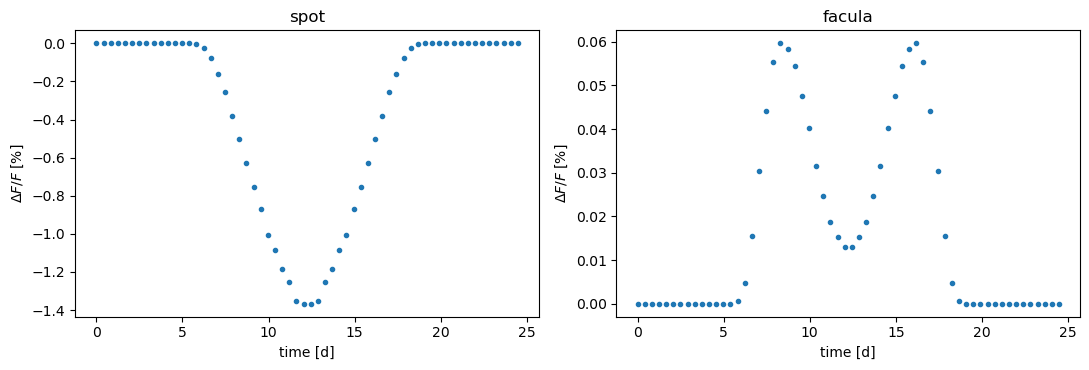

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, name in zip(axes, ['spot', 'facula']):
    ax.plot(photometry[name].obs_times, relative_flux(photometry[name]), '.')
    ax.set_title(name)
    ax.set_xlabel('time [d]')
    ax.set_ylabel('$\\Delta F / F$ [%]')
plt.tight_layout()
plt.show()

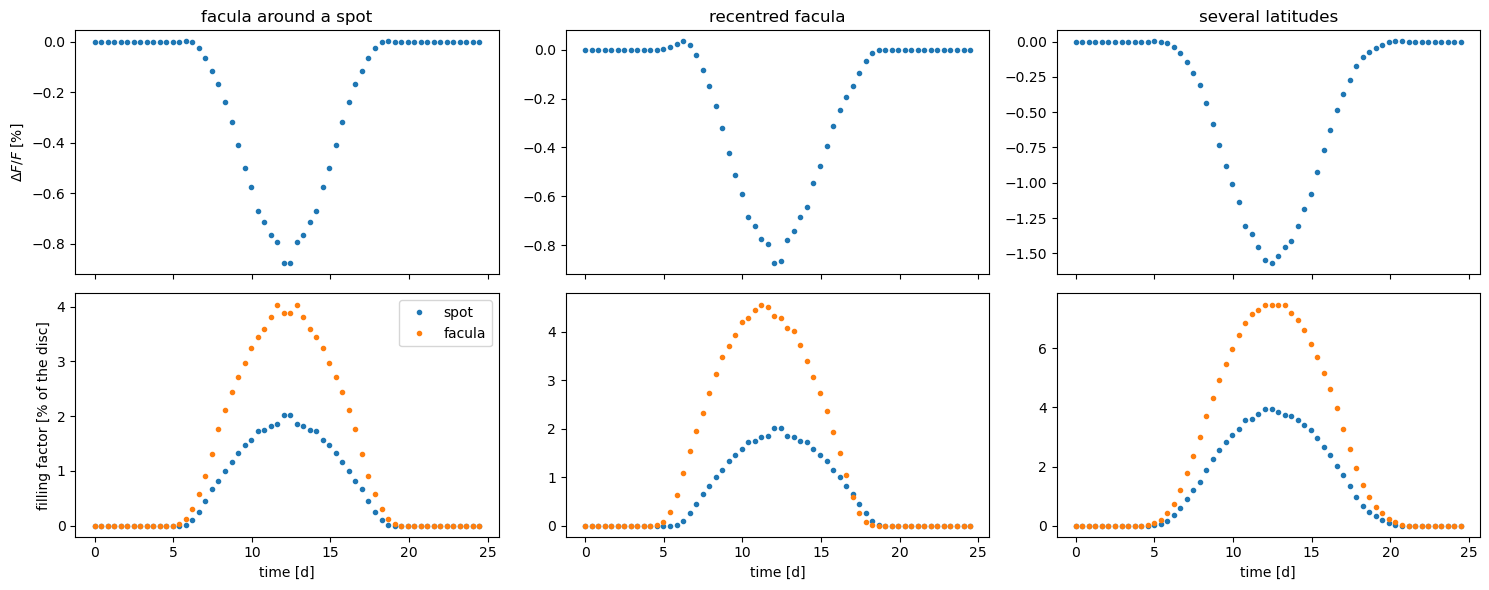

In [8]:
multi = ['facula around a spot', 'recentred facula', 'several latitudes']
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for j, name in enumerate(multi):
    ss = photometry[name]
    axes[0, j].plot(ss.obs_times, relative_flux(ss), '.')
    axes[0, j].set_title(name)
    axes[1, j].plot(ss.obs_times, ss.ff_sp, '.', label='spot')
    axes[1, j].plot(ss.obs_times, ss.ff_fc, '.', label='facula')
    axes[1, j].set_xlabel('time [d]')
axes[0, 0].set_ylabel('$\\Delta F / F$ [%]')
axes[1, 0].set_ylabel('filling factor [% of the disc]')
axes[1, 0].legend()
plt.tight_layout()
plt.show()

### A spot that grows and decays

A region exists between `appearance_time` and `appearance_time + lifetime` [days] (by default always). Outside its life its radius is 0. By default the radius is constant (`size`) during its life. With `active_region(..., evolution=law)` any evolution law can be given: a function `law(dt, size)` that returns the radius [deg], where `dt = t − appearance_time` [days] is an array of times. The function can be written with numpy (vectorised) or for one time at a time (with `if`/`else`, `math`, ...): both work. A radius ≤ 0 (or NaN) simply means that the region is not there at that time. Outside the lifetime the region is absent whatever the law gives, so the law does not need to take care of the times before the appearance or after the disappearance of the region.

Here the **area** of the spot grows linearly during `t_grow` = 4 days and then decays linearly during `t_decay` = 30 days. The linear decay of the area is the Gnevyshev-Waldmeier rule observed for sunspots. The radius is then `size · sqrt(area / maximum area)`. The spot appears at t = 6 d (`appearance_time`), is at its maximum (10°) at t = 10 d and disappears at t = 40 d (`lifetime` = 34 d, the end of the decay). We simulate two rotations: the spot crosses the disc centre at t = P/2 ≈ 12.2 d, when it is almost at its maximum, and again one rotation later, at t ≈ 36.7 d, when it is small. The light curve is compared with that of a spot with a constant radius of 10° that is always present, and with one that appears suddenly at t = 20 d and lives 25 days: it is absent at the first crossing of the disc centre and present at the second one. The radius used at every epoch is stored in `regions_pos` (in radians).

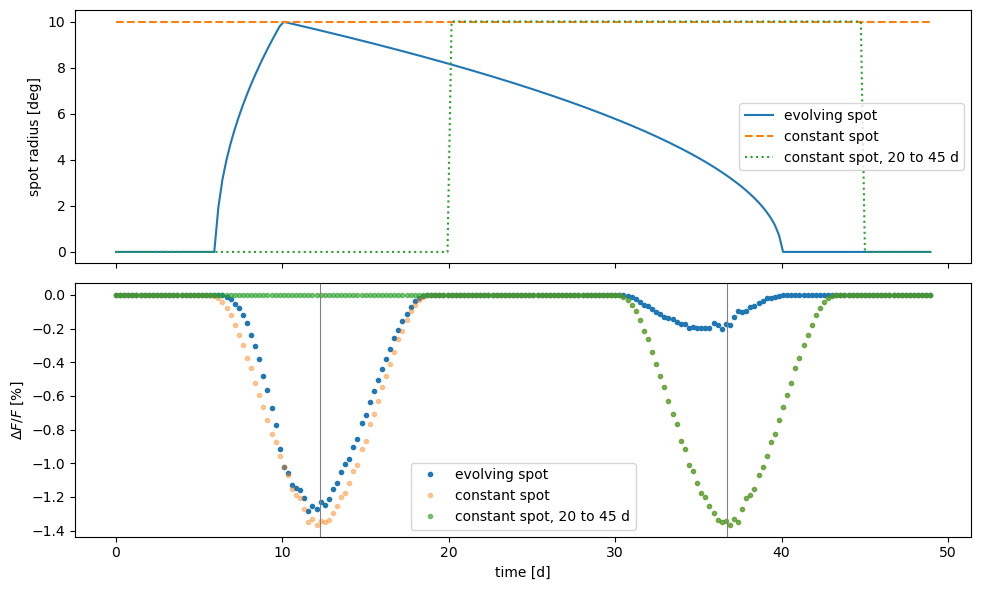

In [9]:
def growth_decay(dt, size, t_grow=4.0, t_decay=30.0):
    """Area growing linearly during t_grow and decaying linearly during t_decay [days]; returns the radius [deg]."""
    area = np.where(dt < t_grow, dt / t_grow, 1 - (dt - t_grow) / t_decay)    # area / maximum area, < 0 outside the life of the spot
    return size * np.sqrt(np.clip(area, 0, None))                               # (clip only because sqrt needs >= 0)

time_evol = np.linspace(0, 2 * rotation_period, 200)                          # two rotations [days]

def simulate_evolution(regions):
    ss = StarSim(time_evol, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=regions, mode=['photometry'],
                 stellar_radius=stellar_radius,
                 flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid)
    ss.generate_timeseries()
    return ss

evolving = simulate_evolution([active_region('sp', 10, 90, 180, appearance_time=6, lifetime=34, evolution=growth_decay)])
constant = simulate_evolution([active_region('sp', 10, 90, 180)])                                  # always present
limited = simulate_evolution([active_region('sp', 10, 90, 180, appearance_time=20, lifetime=25)])   # 20 <= t <= 45 d

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(time_evol, np.rad2deg(evolving.regions_pos[:, 0, 2]), label='evolving spot')
ax1.plot(time_evol, np.rad2deg(constant.regions_pos[:, 0, 2]), '--', label='constant spot')
ax1.plot(time_evol, np.rad2deg(limited.regions_pos[:, 0, 2]), ':', label='constant spot, 20 to 45 d')
ax1.set_ylabel('spot radius [deg]')
ax1.legend()
ax2.plot(time_evol, relative_flux(evolving), '.', label='evolving spot')
ax2.plot(time_evol, relative_flux(constant), '.', alpha=0.4, label='constant spot')
ax2.plot(time_evol, relative_flux(limited), '.', alpha=0.6, label='constant spot, 20 to 45 d')
for k in (0.5, 1.5):
    ax2.axvline(k * rotation_period, color='grey', lw=0.8)                    # the spot crosses the disc centre
ax2.set_ylabel('$\\Delta F / F$ [%]')
ax2.set_xlabel('time [d]')
ax2.legend()
plt.tight_layout()
plt.show()

### A transiting planet

A planet is a `planet` object (`planet.py`), given to `StarSim(..., planet=...)`. Several planets are given as a list, `planet=[planet_b, planet_c, ...]`, each with its own orbit, size and spin-orbit angle. `planet=None`, the default, means no planet. `StarSim` then places it in front of the star. The planet is a dark disc: it covers part of the cells (`ff_pl`), and this fraction is removed from the quiet, spot and facula parts of each cell, so that it gives no flux. The fraction is the exact projected area of the planet disc inside every cell (a cell is an annular sector on the sky), so the transit depth is right for any planet, also much smaller than a cell: an Earth (0.009 R★) needs no more rings than a Jupiter. The old StarSim used a linear ramp in the distance between the cell and the planet, which made the planets smaller than a cell much too deep (×8 for 0.01 R★ with 15 rings); `StarSim(..., planet_coverage='ramp')` reproduces it, only to compare with old results. Its parameters are:

| parameter of `planet(...)` | meaning |
|---|---|
| `planet_period` | orbital period [days] |
| `planet_transit_t0` | time of the centre of the transit [days] |
| `planet_radius` | radius [stellar radii] |
| `planet_semi_major_axis` | semi-major axis [stellar radii] |
| `planet_impact_param` | impact parameter b [stellar radii]: 0 = the planet crosses the disc centre |
| `planet_esinw`, `planet_ecosw` | e·sin ω and e·cos ω (0, 0 = circular orbit) |
| `planet_spin_orbit_angle` | projected spin-orbit angle λ [rad]: angle on the sky between the projected rotation axis of the star and the projected normal of the orbit, i.e. between the stellar equator and the path of the planet on the disc. 0 = aligned prograde orbit, π/2 = polar, π = retrograde |
| `planet_semi_amplitude` | RV semi-amplitude K of the star induced by the planet [m/s]. Only used in `'ccf'` mode: the Keplerian RV `K·[cos(f+ω) + e·cos ω]` (`planet.keplerian_rv`, also stored in `rv_kepler`) is added to `rv_var` |

The `planet` object also gives its position on the disc at any time (`positions(times)`: ρ, θ and radius; `StarSim` stores those of all its planets in `planet_pos`, shape `(n_times, n_planets, 3)`), the Keplerian RV of the star (`keplerian_rv(times)`), the inclination of its orbit (`orbital_inclination()`) and the true (3D) obliquity ψ, the angle between the rotation axis of the star and the normal of the orbit (`obliquity(inclination)`, with cos ψ = cos i★ cos i_p + sin i★ sin i_p cos λ). The simulation needs λ, the angle seen on the sky: ψ alone does not fix the direction of the path of the planet on the disc. With several planets, `ff_pl` is the fraction of the disc covered by all of them and `rv_kepler` the sum of their Keplerian RVs.

Here a planet of 0.1 R* (about Jupiter around the Sun) with a 4 d orbit at a = 10 R* and b = 0, so it crosses the disc along the equator. A transit lasts about 3 hours, much shorter than the 0.4 d step of `time`, so we use a finer time grid around the transit. We centre the transit at t = P_rot/2, when the spot of the `spot` case is at the disc centre, and compare:

* the planet alone, relative to the quiet star: the transit is deeper at the centre than near the limb because of the limb darkening;
* the planet together with the spot, relative to the light curve of the spot alone: when the planet covers the spot it hides a dark region, so less light is lost and the curve rises (the spot crossing).

In [10]:
my_planet = planet(planet_period=4, planet_transit_t0=rotation_period / 2, planet_radius=0.1,
                   planet_semi_major_axis=10, planet_impact_param=0, planet_esinw=0, planet_ecosw=0,
                   planet_spin_orbit_angle=0, planet_semi_amplitude=50)      # K [m/s] is only used in ccf mode (section 7)
time_transit = np.linspace(rotation_period / 2 - 0.12, rotation_period / 2 + 0.12, 121)    # [days]
phot_grids = dict(flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid)

def simulate_transit(regions, with_planet, mode=['photometry'], N_rings=N_rings_phot, grids=phot_grids):
    """StarSim on the transit time grid, with or without the planet."""
    ss = StarSim(time_transit, N_rings, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=differential_rotation, active_regions_map=regions, mode=mode,
                 stellar_radius=stellar_radius, planet=my_planet if with_planet else None, **grids)
    ss.generate_timeseries()
    return ss

planet_alone = simulate_transit([], True)
spot_alone = simulate_transit(scenarios['spot'], False)
planet_spot = simulate_transit(scenarios['spot'], True)
print('maximum ff_pl = %.2f %% of the disc' % planet_alone.ff_pl.max())

maximum ff_pl = 1.00 % of the disc


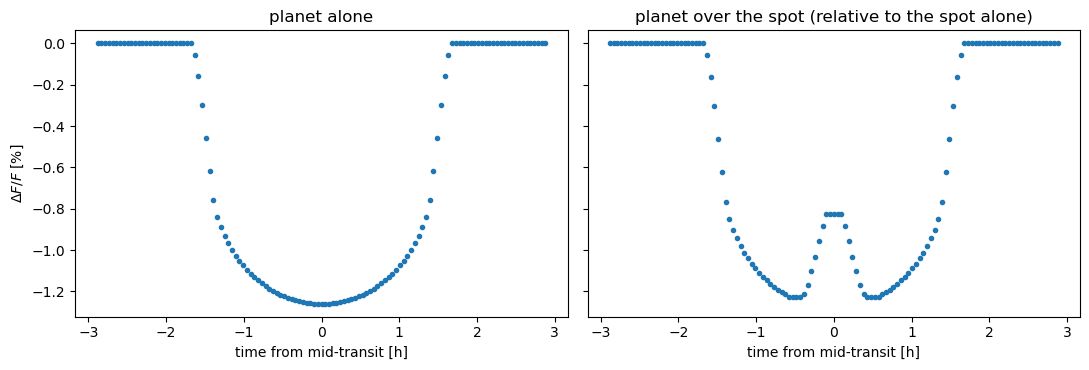

In [11]:
dt_hours = 24 * (time_transit - rotation_period / 2)      # time from the centre of the transit [h]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].plot(dt_hours, relative_flux(planet_alone), '.')
axes[0].set_title('planet alone')
axes[1].plot(dt_hours, 100 * (planet_spot.flux_var / spot_alone.flux_var - 1), '.')
axes[1].set_title('planet over the spot (relative to the spot alone)')
axes[0].set_ylabel('$\\Delta F / F$ [%]')
for ax in axes:
    ax.set_xlabel('time from mid-transit [h]')
plt.tight_layout()
plt.show()

**Two planets.** We add a second, smaller planet c (0.05 R★, P = 6.5 d, b = 0.5) to planet b above, and simulate 16 days with a fine time grid. Planet b transits every 4 days and planet c every 6.5 days. The transit times are chosen so that at t ≈ 12.2 d both planets are in front of the star at the same time. The planets are dark discs; when they overlap each other on the disc (rare), the overlap is counted twice in the cells they share (the occultation of one planet by the other is not modelled).

planet_pos: (3201, 2, 3) (n_times, n_planets, 3)


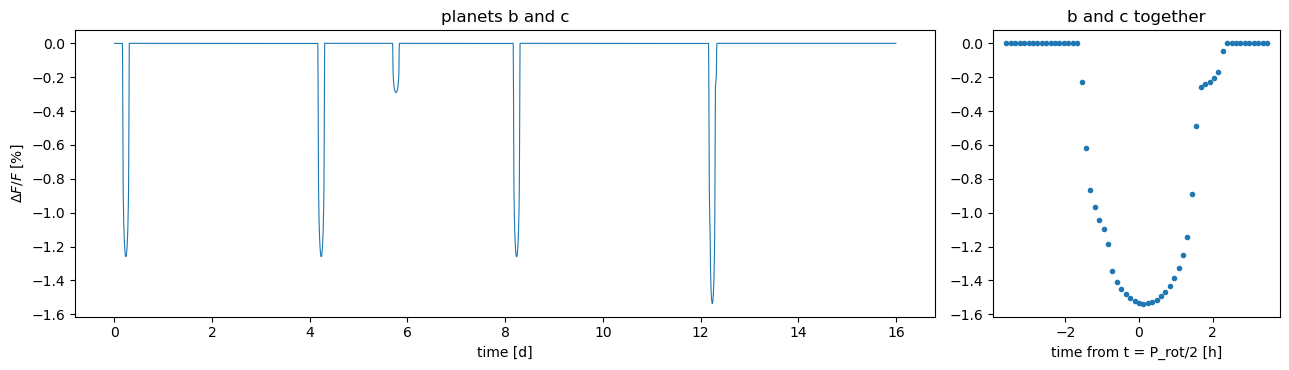

In [12]:
planet_c = planet(planet_period=6.5, planet_transit_t0=rotation_period / 2 + 0.03, planet_radius=0.05,
                  planet_semi_major_axis=14, planet_impact_param=0.5)
time_two = np.linspace(0, 16, 3201)                                            # [days], 7 min steps

two_planets = StarSim(time_two, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
                      mode=['photometry'], stellar_radius=stellar_radius, planet=[my_planet, planet_c], **phot_grids)
two_planets.generate_timeseries()
print('planet_pos:', two_planets.planet_pos.shape, '(n_times, n_planets, 3)')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 1]})
ax1.plot(time_two, relative_flux(two_planets), lw=0.8)
ax1.set_xlabel('time [d]')
ax1.set_ylabel('$\\Delta F / F$ [%]')
ax1.set_title('planets b and c')
zoom_t = np.abs(time_two - rotation_period / 2) < 0.15                         # simultaneous transits
ax2.plot(24 * (time_two[zoom_t] - rotation_period / 2), relative_flux(two_planets)[zoom_t], '.')
ax2.set_xlabel('time from t = P_rot/2 [h]')
ax2.set_title('b and c together')
plt.tight_layout()
plt.show()

## 4. Low resolution spectroscopy: a facula transit (no rotation)

`flux_grid(..., mode='spectroscopy')` keeps the whole spectrum of every cell instead of integrating it: `grid` has the shape `(n_cells, n_wavelengths)`. With `stellar_rotation=False` all the cells of a ring have the same spectrum (no Doppler shift). `StarSim(mode=['spectroscopy'])` then returns `spec_var`, an array `(n_times, n_wavelengths)` with the disk-integrated spectrum at every epoch.

The grids are much bigger than in photometry, so we use 20 rings (about 1000 cells). We simulate the facula of section 3 and plot, for a few epochs, the spectrum and its relative difference with the spectrum at t = 0, when the facula is on the far side and the star is the quiet one.

In [13]:
N_rings_spec = 60

def spectroscopy_grid(flux, typ, lo, hi):
    """Spectrum of every cell between lo and hi [A], without rotation."""
    g = flux_grid(N_rings_spec, flux, typ, None, lo, hi, rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=False, mode='spectroscopy',
                  differential_rotation=differential_rotation)
    g.built_grid()
    return g

spec_grid_quiet = spectroscopy_grid(flux_quiet_low, 'quiet', 3800, 8000)
spec_grid_fc = spectroscopy_grid(flux_fc_low, 'fc', 3800, 8000)
spec_grid_sp = spectroscopy_grid(flux_sp_low, 'sp', 3800, 8000)

facula_low = simulate(scenarios['facula'], ['spectroscopy'], N_rings_spec,
                      flux_grid_qp=spec_grid_quiet.grid, flux_grid_sp=spec_grid_sp.grid, flux_grid_fc=spec_grid_fc.grid)
print('spec_var:', facula_low.spec_var.shape, '(n_times, n_wavelengths)')

spec_var: (60, 4199) (n_times, n_wavelengths)


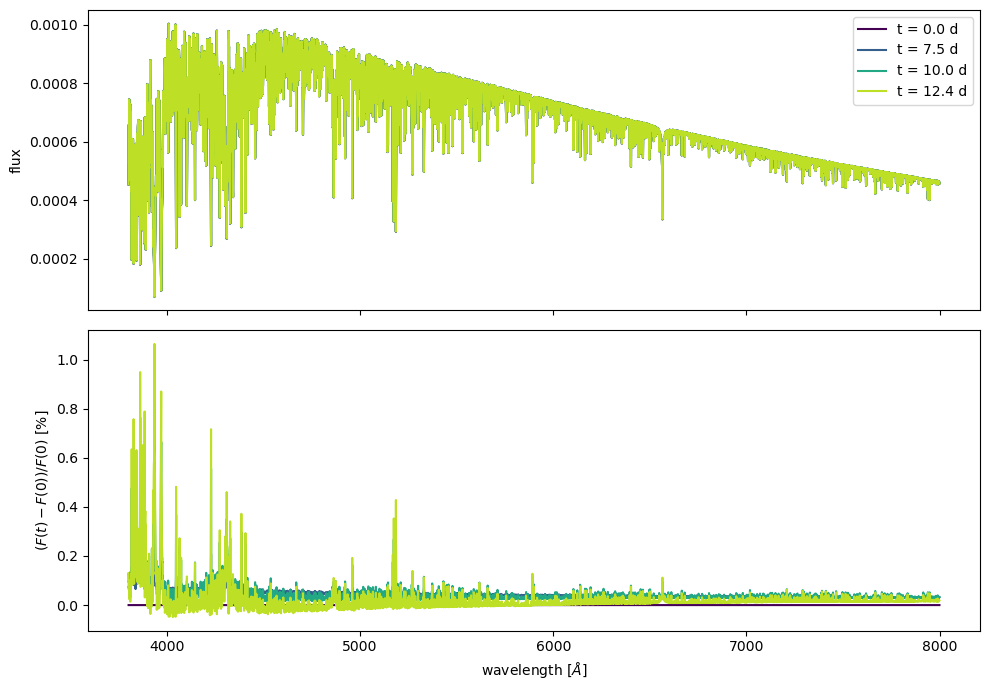

In [14]:
def plot_spectra_and_differences(wv, spec, fractions=(0.0, 0.30, 0.40, 0.50), xlim=None):
    """Spectra at some epochs (given as fractions of the rotation period) and their relative difference with the spectrum at time = 0."""
    idx = [int(np.argmin(np.abs(time - f * rotation_period))) for f in fractions]
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(idx)))
    shown = np.ones(len(wv), dtype=bool) if xlim is None else (wv >= xlim[0]) & (wv <= xlim[1])    # only these wavelengths are plotted
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        for k, color in zip(idx, colors):
            label = 't = %.1f d' % time[k]
            ax1.plot(wv[shown], spec[k][shown], color=color, label=label)
            ax2.plot(wv[shown], 100 * (spec[k][shown] / spec[0][shown] - 1), color=color, label=label)
    ax1.set_ylabel('flux')
    ax2.set_ylabel('$(F(t) - F(0)) / F(0)$ [%]')
    ax2.set_xlabel('wavelength [$\\AA$]')
    ax1.legend()
    if xlim is not None:
        ax1.set_xlim(xlim)
    plt.tight_layout()
    plt.show()

plot_spectra_and_differences(spec_grid_quiet.wv, facula_low.spec_var)

### A planet transit in spectroscopy

The planet of section 3 (0.1 R*, b = 0), now with the spectroscopy grids. The planet blocks the light of the cells it covers, and the limb darkening depends on the wavelength: it is stronger in the blue. So the transit is **chromatic**. At mid-transit the planet covers the bright disc centre and the transit is deeper in the blue. During ingress and egress it covers the limb, which is darker in the blue, so there the transit is deeper in the red.

We plot the light curve integrated over a blue and a red band, and the transit depth `1 − F(t)/F_out` as a function of wavelength at mid-transit and during ingress (`F_out` is the spectrum before the transit). With 20 rings the cells are about 0.08 R* wide. The area hidden by the planet is exact in every cell, but the intensity is the same over a cell, so the limb darkening under the planet is sampled at the resolution of the rings (use more rings for precise transit shapes near the limb).

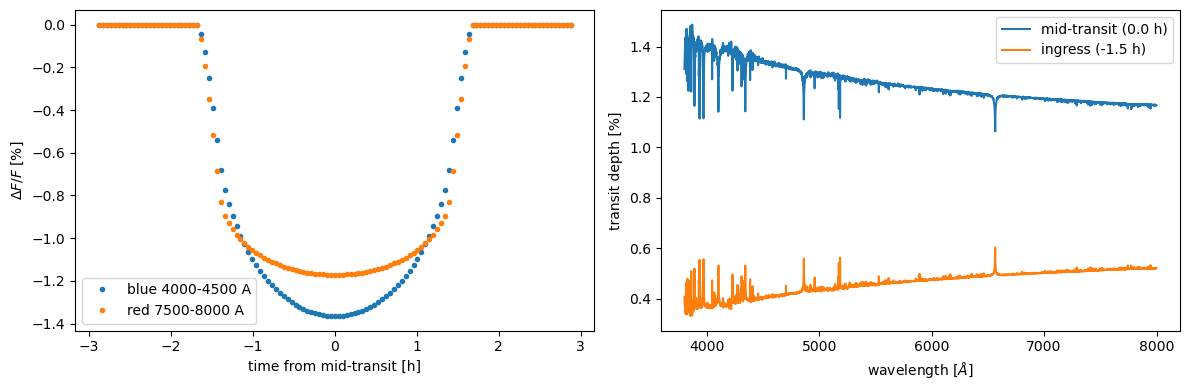

In [15]:
planet_spec = simulate_transit([], True, mode=['spectroscopy'], N_rings=N_rings_spec,
                               grids=dict(flux_grid_qp=spec_grid_quiet.grid, flux_grid_sp=spec_grid_sp.grid, flux_grid_fc=spec_grid_fc.grid))
wv_spec = spec_grid_quiet.wv
F_out = planet_spec.spec_var[0]                         # spectrum before the transit
dt_hours = 24 * (time_transit - rotation_period / 2)    # time from the centre of the transit [h]

bands = {'blue 4000-4500 A': (4000, 4500), 'red 7500-8000 A': (7500, 8000)}
epochs = {'mid-transit': 0.0, 'ingress': -1.5}           # [h] from the centre of the transit

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for label, (lo, hi) in bands.items():
    band = (wv_spec >= lo) & (wv_spec <= hi)
    flux_band = planet_spec.spec_var[:, band].sum(axis=1)       # flux in the band
    ax1.plot(dt_hours, 100 * (flux_band / flux_band[0] - 1), '.', label=label)
ax1.set_xlabel('time from mid-transit [h]')
ax1.set_ylabel('$\\Delta F / F$ [%]')
ax1.legend()
with np.errstate(divide='ignore', invalid='ignore'):
    for label, h in epochs.items():
        k = int(np.argmin(np.abs(dt_hours - h)))
        ax2.plot(wv_spec, 100 * (1 - planet_spec.spec_var[k] / F_out), label='%s (%.1f h)' % (label, dt_hours[k]))
ax2.set_xlabel('wavelength [$\\AA$]')
ax2.set_ylabel('transit depth [%]')
ax2.legend()
plt.tight_layout()
plt.show()

## 5. High resolution spectroscopy: a facula transit (no rotation)

The same with the high resolution spectra. A high resolution spectrum has hundreds of thousands of wavelengths, and `grid` stores one spectrum per cell, so we keep only a small wavelength window (`cut_spectra`) and use 20 rings. The spectra are plotted in a zoom of the window where individual lines can be seen.

In [16]:
N_rings_hr = 20
wl_window = (5000.0, 5004.0)         # [A] part of the spectrum that is simulated
zoom = (5000.25, 5001.2)             # [A] part that is plotted

hr_quiet = cut_spectra(flux_quiet, *wl_window)
hr_fc = cut_spectra(flux_fc, *wl_window)
hr_sp = cut_spectra(flux_sp, *wl_window)

def hr_spectroscopy_grid(flux, typ, stellar_rotation=False, incl=inclination):
    g = flux_grid(N_rings_hr, flux, typ, None, *wl_window, rotation_period=rotation_period, inclination=incl,
                  stellar_radius=stellar_radius, stellar_rotation=stellar_rotation, mode='spectroscopy',
                  differential_rotation=differential_rotation)
    g.built_grid()
    return g

hr_grid_quiet = hr_spectroscopy_grid(hr_quiet, 'quiet')
hr_grid_fc = hr_spectroscopy_grid(hr_fc, 'fc')
hr_grid_sp = hr_spectroscopy_grid(hr_sp, 'sp')

facula_high = simulate(scenarios['facula'], ['spectroscopy'], N_rings_hr,
                       flux_grid_qp=hr_grid_quiet.grid, flux_grid_sp=hr_grid_sp.grid, flux_grid_fc=hr_grid_fc.grid)
print('spec_var:', facula_high.spec_var.shape, '(n_times, n_wavelengths)')

spec_var: (60, 401) (n_times, n_wavelengths)


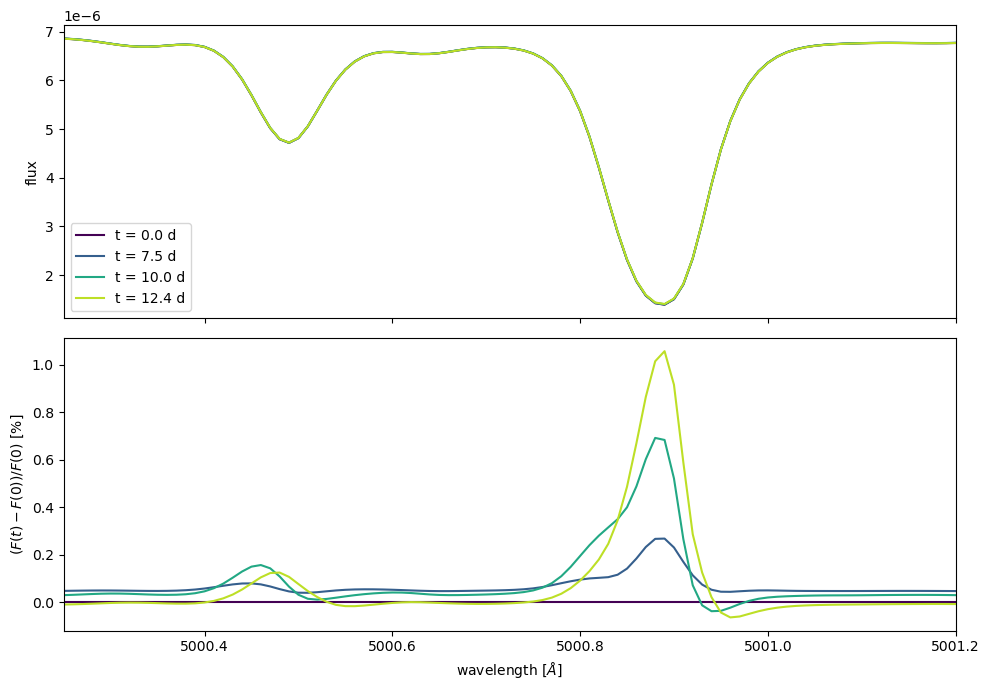

In [17]:
plot_spectra_and_differences(hr_grid_quiet.wv, facula_high.spec_var, xlim=zoom)

## 6. Disk-integrated quiet photosphere, with and without rotation

`flux_grid(..., stellar_rotation=True)` Doppler shifts the spectrum of every cell by the rotation velocity of the cell (`vsini`, the projected equatorial velocity 2πR cos(i) / P with i the inclination defined above, times a factor that depends on the position of the cell, and Ω(lat)/Ω_eq for the solar differential rotation set in section 2), so the disk-integrated spectrum is the sum over the cells of spectra shifted towards the blue on the approaching side and towards the red on the receding side: the lines are broadened. We use the solar inclination, a rotation axis tilted by 7.25° with respect to the plane of the sky, and compare with the spectrum of the same star at rest.

In [18]:
inclination_sun = np.deg2rad(7.25)       # [rad]

grid_rest = hr_spectroscopy_grid(hr_quiet, 'quiet', stellar_rotation=False, incl=inclination_sun)
grid_rot = hr_spectroscopy_grid(hr_quiet, 'quiet', stellar_rotation=True, incl=inclination_sun)

disk_rest = grid_rest.grid.sum(axis=0)       # disk-integrated spectra
disk_rot = grid_rot.grid.sum(axis=0)
print('vsini = %.2f km/s' % (grid_rot.vsini / 1000))

vsini = 2.05 km/s


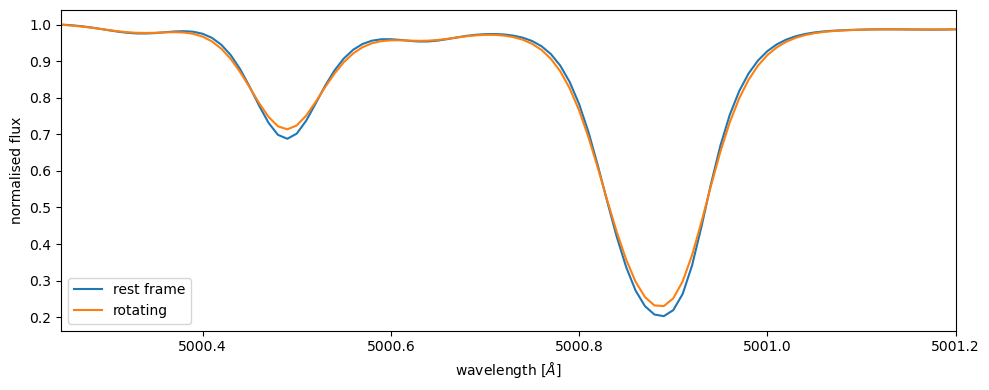

In [19]:
in_rest = (grid_rest.wv >= zoom[0]) & (grid_rest.wv <= zoom[1])      # only the zoom is plotted
in_rot = (grid_rot.wv >= zoom[0]) & (grid_rot.wv <= zoom[1])
norm = disk_rest[in_rest].max()                                       # same normalisation for both spectra

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid_rest.wv[in_rest], disk_rest[in_rest] / norm, label='rest frame')
ax.plot(grid_rot.wv[in_rot], disk_rot[in_rot] / norm, label='rotating')
ax.set_xlim(zoom)
ax.set_ylabel('normalised flux')
ax.set_xlabel('wavelength [$\\AA$]')
ax.legend()
plt.tight_layout()
plt.show()

## 7. CCF mode: RV, BIS and FWHM

**Idea.** The CCF is the cross-correlation of the spectrum with a mask of lines (here `HARPS_G20_mps_friendly.mas`). `CCF_grid` computes the CCF of the rings. `StarSim(mode=['ccf'])` places the CCF of every ring on the velocity axis, shifted by the rotation velocity of each cell (Doppler shift), and sums over the cells with the filling factors:

`ccf(t) = Σ_cells [ ff_quiet · ccf_quiet + ff_sp · ccf_spot + ff_fc · ccf_facula ]`

Finally `compute_ccf_params` fits a gaussian to every CCF (`rv_var`, `fwhm_var`, `contrast_var`) and computes the bisector span (`bis_var`: mean velocity of the bisector at 10-40 % of the CCF height minus the mean at 60-90 %). All of them are in m/s, except the contrast.

**`CCF_grid` has two steps.** `compute_ccf()` gives the CCF of the rings, `rv_treatment()` the velocity axis on which they are placed, and `built_grid()` runs both.

**Why `mu_ratio`.** The CCF of a ring is normalised to the continuum of its own spectrum, so by itself it does not know that the ring is darker than the disc centre (limb darkening), or that a spot is darker than the photosphere. Without that, a spot would hardly unbalance the rotation of the star and the RV would barely change. With `mu_ratio` the CCF of a ring is multiplied by the brightness of the ring relative to the quiet disc centre. We take these brightness ratios from the low resolution flux grids (same limb darkening, same spot and facula contrast as in the photometry), in the wavelength range of the mask.

**CCFs of the rings.** The high resolution spectra at the 10 μ angles are given to `CCF_grid`. The CCF of each of these 10 spectra is computed first (`ccf_mu`). The CCF of every ring is then interpolated linearly in μ between them, and below μ = 0.1 it is the CCF at the smallest μ (the brightness of the ring is given by `mu_ratio`). This happens in the rest frame of the surface, before the Doppler shift of the rotation, which `StarSim` adds afterwards, cell by cell. Only 10 CCFs are computed whatever the number of rings, instead of one per ring. With `CCF_grid(..., interpolation='spectrum')` the spectrum is interpolated in μ instead and one CCF is computed per ring. The two agree closely: in a test with lines whose depth, width and convective blueshift change with μ, the RV, FWHM and BIS signals differed by about 0.02 m/s. Every ring therefore keeps the line shape of the spectra, and in particular its bisector: the convective blueshift of the quiet photosphere and its reduction in the faculae, and their variation with μ.

**RV treatment.** No bisector is removed: the CCF of every ring is placed at the velocity given by its own spectrum. On top of that a bisector can be added, multiplied by `convective_blueshift`. Here only the spot gets one: the Dumusque bisector, with the polynomial without normalization (`dumusque_bisector(normalization=False)`) and `convective_blueshift = 1`. Nothing is added to the quiet star and the faculae, so their RV changes come from the flux of the regions and from the line shapes of their spectra.

In [20]:
N_rings_ccf = 30
inclination_sun = 0      # [rad]

mask_path = '/Users/sophiestucki/starsim/starsim/masks/HARPS_G20_mps_friendly.mas'
wvm, fm = mask_weights(mask_path)                  # wavelengths [A] and weights of the mask lines
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]

convective_blueshift = {'quiet': 0, 'fc': 0, 'sp': 1}     # factor of the added bisector (0 = none)
bisector = {'quiet': None, 'fc': None,
            'sp': dumusque_bisector(normalization=False)}  # Dumusque bisector, polynomial without normalization

In [21]:
def make_ccf_grid(flux, typ):
    g = CCF_grid(N_rings_ccf, flux, rv_grid, wvm, fm, convective_blueshift=convective_blueshift[typ],
                 phoenix_resolution=True, normalization=False)
    g.built_grid(bisector=bisector[typ])            # compute_ccf() and rv_treatment()
    return g

ccf_quiet = make_ccf_grid(flux_quiet, 'quiet')
ccf_fac = make_ccf_grid(flux_fc, 'fc')
ccf_spot = make_ccf_grid(flux_sp, 'sp')

Now the same five cases as in the photometry. Each simulation returns the CCF of every epoch and its parameters. The reference is the first epoch, when no region is visible (this is checked).

In [22]:
ccf_runs = {}
for name, regions in scenarios.items():
    ss = simulate(regions, ['ccf'], N_rings_ccf, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
    assert ss.ff_sp[0] == 0 and ss.ff_fc[0] == 0, 'a region is visible at t = 0: the first epoch is not the quiet star'
    ccf_runs[name] = ss
print('ccf_var:', ss.ccf_var.shape, '(n_times, n_rv)')

ccf_var: (60, 1441) (n_times, n_rv)


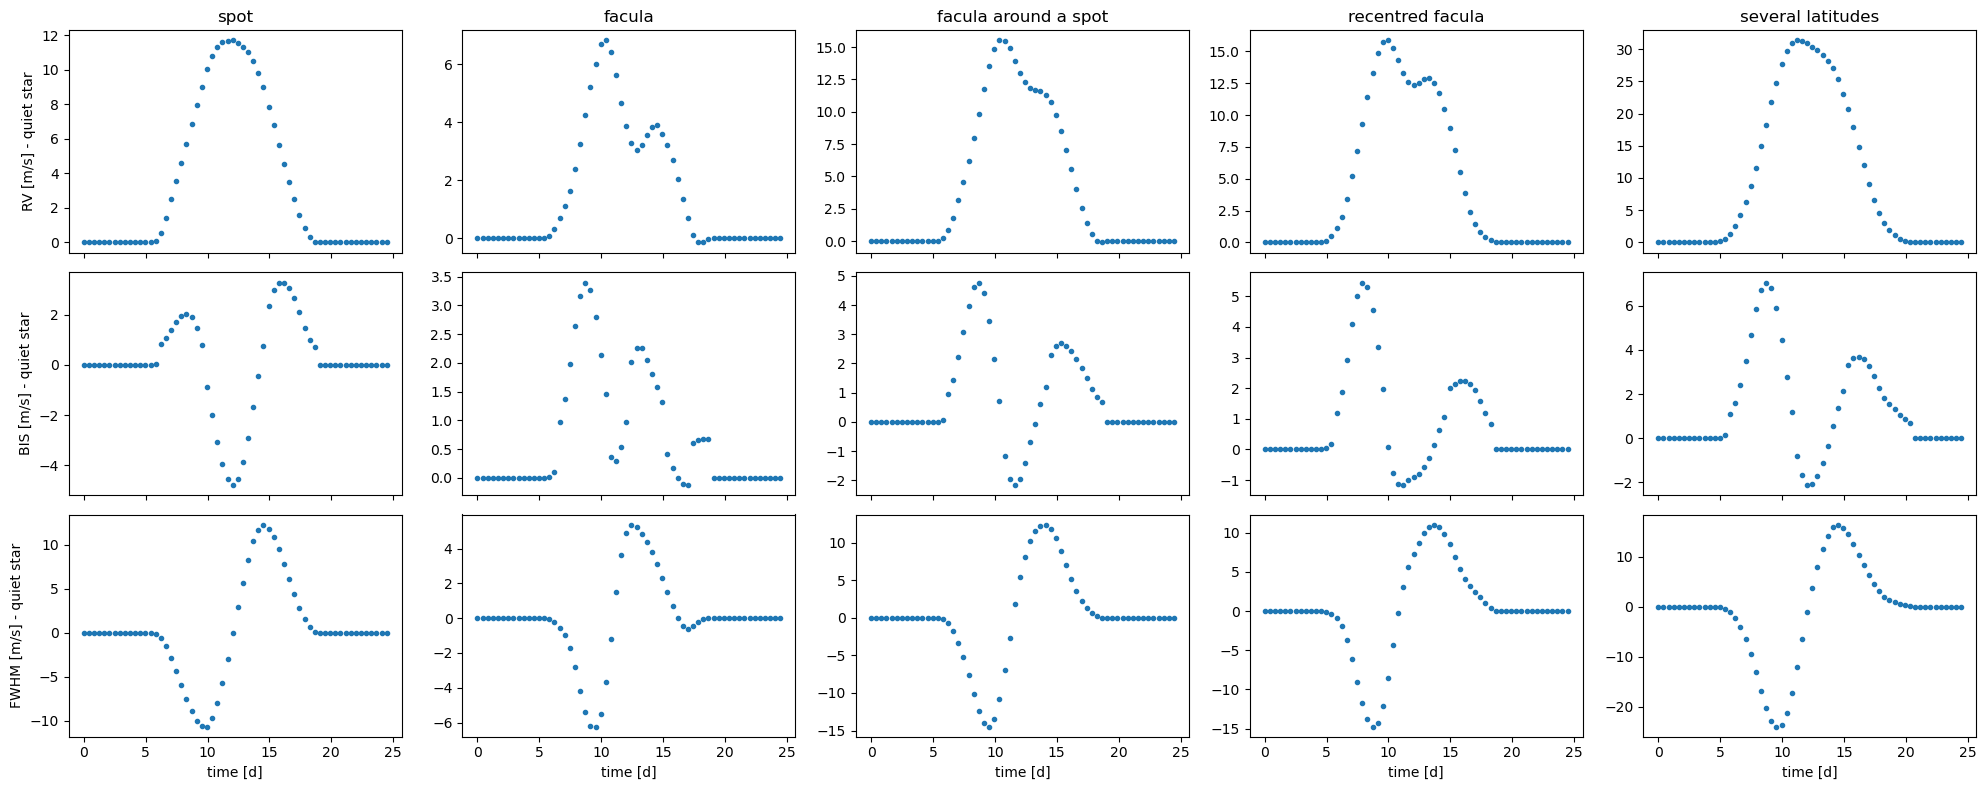

In [23]:
quantities = [('rv_var', 'RV [m/s]'), ('bis_var', 'BIS [m/s]'), ('fwhm_var', 'FWHM [m/s]')]
names = list(scenarios)
fig, axes = plt.subplots(3, len(names), figsize=(4 * len(names), 8), sharex=True)
for j, name in enumerate(names):
    ss = ccf_runs[name]
    for i, (attr, label) in enumerate(quantities):
        values = getattr(ss, attr)
        axes[i, j].plot(ss.obs_times, values - values[0], '.')       # difference with the quiet star (first epoch)
        if j == 0:
            axes[i, j].set_ylabel(label + ' - quiet star')
    axes[0, j].set_title(name)
    axes[-1, j].set_xlabel('time [d]')
plt.tight_layout()
plt.show()

### A planet transit in the CCF: Keplerian RV and Rossiter-McLaughlin effect

The planet of section 3, now in `'ccf'` mode. Its `planet_semi_amplitude = 50` m/s is used here. Two things change the RV:

* **the Keplerian orbit**: `my_planet.keplerian_rv(times)` gives the reflex motion of the star, `K·[cos(f+ω) + e·cos ω]`. It is stored in `rv_kepler` and added to `rv_var`;
* **the Rossiter-McLaughlin effect**: the star rotates, so one half of the disc approaches us (blue shifted) and the other half recedes (red shifted). The planet first hides part of one half and then part of the other, so the CCF loses light first on one side of the line and then on the other: the RV goes up and then down (or the opposite, depending on the direction of the orbit). The amplitude is about (Rp/R*)² · vsini, here 0.01 × 2 km/s ≈ 20 m/s. The planet also changes the shape of the CCF, so the FWHM and the BIS change during the transit.

The reference is the quiet star (first epoch of the CCF runs above). `rv_var − rv_kepler` is the RV without the orbit, i.e. the Rossiter-McLaughlin anomaly alone.

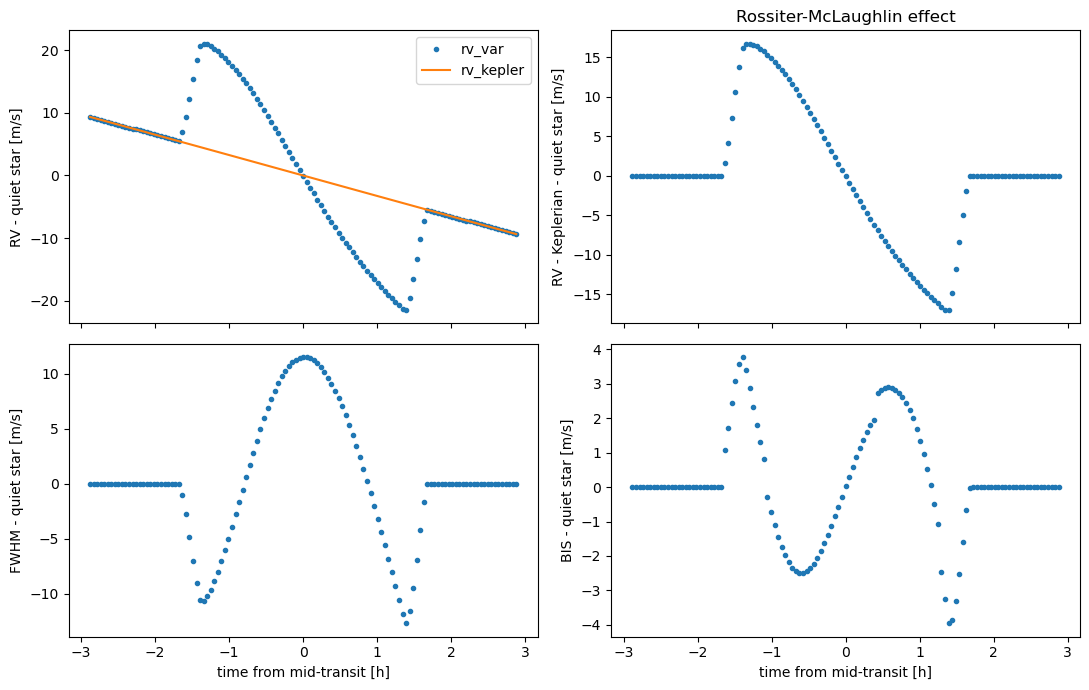

In [24]:
planet_ccf = simulate_transit([], True, mode=['ccf'], N_rings=N_rings_ccf,
                              grids=dict(ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac))
quiet = ccf_runs['spot']                                # its first epoch is the quiet star (checked above)
dt_hours = 24 * (time_transit - rotation_period / 2)    # time from the centre of the transit [h]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axes[0, 0].plot(dt_hours, planet_ccf.rv_var - quiet.rv_var[0], '.', label='rv_var')
axes[0, 0].plot(dt_hours, planet_ccf.rv_kepler, '-', label='rv_kepler')
axes[0, 0].set_ylabel('RV - quiet star [m/s]')
axes[0, 0].legend()
axes[0, 1].plot(dt_hours, planet_ccf.rv_var - planet_ccf.rv_kepler - quiet.rv_var[0], '.')
axes[0, 1].set_ylabel('RV - Keplerian - quiet star [m/s]')
axes[0, 1].set_title('Rossiter-McLaughlin effect')
axes[1, 0].plot(dt_hours, planet_ccf.fwhm_var - quiet.fwhm_var[0], '.')
axes[1, 0].set_ylabel('FWHM - quiet star [m/s]')
axes[1, 1].plot(dt_hours, planet_ccf.bis_var - quiet.bis_var[0], '.')
axes[1, 1].set_ylabel('BIS - quiet star [m/s]')
for ax in axes[1]:
    ax.set_xlabel('time from mid-transit [h]')
plt.tight_layout()
plt.show()

**Spin-orbit angle.** The shape of the Rossiter-McLaughlin anomaly depends on the projected spin-orbit angle λ, i.e. on which parts of the rotating disc the planet covers. We use the same planet with b = 0.3 and λ = 0°, 45°, 90° and 180°:

* λ = 0° (aligned, prograde): the planet first covers the approaching half (blue shifted), then the receding half: the RV goes up, then down;
* λ = 45°: the path crosses less of the velocity field, the amplitude is smaller and asymmetric;
* λ = 90° (polar orbit): the path is parallel to the rotation axis, on one side of it (b ≠ 0), so the planet always covers the same kind of velocities: the anomaly has a single sign;
* λ = 180° (retrograde): the opposite of the aligned case.

Left: path of the planet on the disc (`planet_pos`; the rotation axis of the star is vertical). Right: the anomaly. For each planet `obliquity(inclination)` gives the true obliquity ψ (here the star is seen equator-on and the orbit is almost edge-on, so ψ ≈ λ).

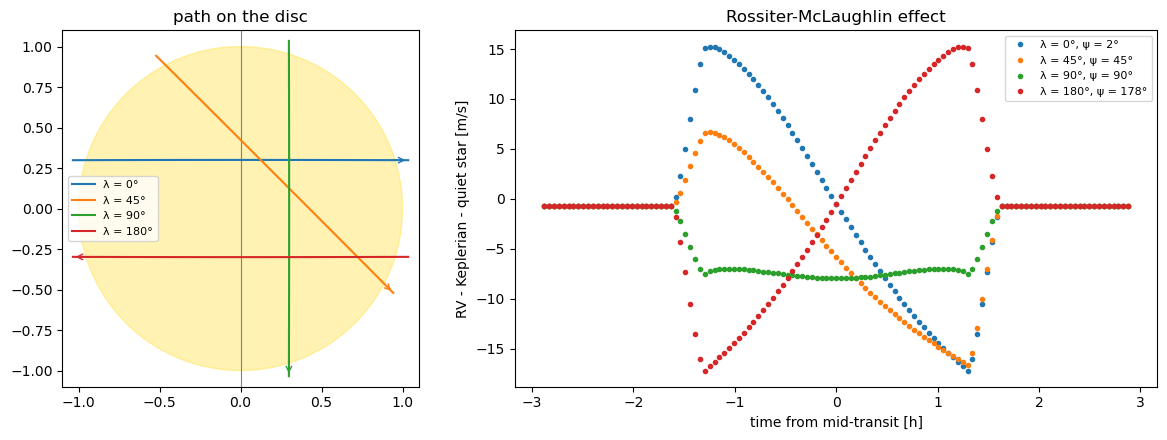

In [25]:
def rm_for_lambda(lam_deg, b=0.3):
    pl = planet(planet_period=4, planet_transit_t0=rotation_period / 2, planet_radius=0.1, planet_semi_major_axis=10,
                planet_impact_param=b, planet_spin_orbit_angle=np.deg2rad(lam_deg))
    ss = StarSim(time_transit, N_rings_ccf, inclination=inclination, rotation_period=rotation_period, mode=['ccf'],
                 stellar_radius=stellar_radius, planet=pl, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
    ss.generate_timeseries()
    return pl, ss

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
ax1.add_patch(plt.Circle((0, 0), 1, color='gold', alpha=0.3))
ax1.axvline(0, color='grey', lw=0.8)                                           # projected rotation axis
for lam in (0, 45, 90, 180):
    pl, ss = rm_for_lambda(lam)
    rho, theta = ss.planet_pos[:, 0, 0], ss.planet_pos[:, 0, 1]
    on_disc = rho < 1 + pl.planet_radius
    line, = ax1.plot((rho * np.cos(theta))[on_disc], (rho * np.sin(theta))[on_disc], label='λ = %d°' % lam)
    ax1.annotate('', xy=((rho * np.cos(theta))[on_disc][-1], (rho * np.sin(theta))[on_disc][-1]),
                 xytext=((rho * np.cos(theta))[on_disc][-5], (rho * np.sin(theta))[on_disc][-5]),
                 arrowprops=dict(arrowstyle='->', color=line.get_color()))
    ax2.plot(dt_hours, ss.rv_var - ss.rv_kepler - quiet.rv_var[0], '.', color=line.get_color(),
             label='λ = %d°, ψ = %.0f°' % (lam, np.rad2deg(pl.obliquity(inclination))))
ax1.set_aspect('equal')
ax1.set_xlim(-1.1, 1.1)
ax1.set_ylim(-1.1, 1.1)
ax1.set_title('path on the disc')
ax1.legend(fontsize=8)
ax2.set_xlabel('time from mid-transit [h]')
ax2.set_ylabel('RV - Keplerian - quiet star [m/s]')
ax2.set_title('Rossiter-McLaughlin effect')
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Going further.**

* To add the convective blueshift, set `convective_blueshift` above (it multiplies the Dumusque bisector) or give another bisector `f(mu) -> p(ccf)` to `built_grid(bisector=...)`, for instance one that depends on μ.
* `CCF_grid(..., mu_ratio=None)` computes the CCF of every ring from its own spectrum (it then needs the spectra at several μ).
* With `instrument='HARPS-N'`, `blaze_function=(wavelengths, blaze)` and `instrumental_efficiency`, the CCF is computed order by order after degrading the spectrum to the resolution of the instrument (example below).

### Instrumental effects: CCFs order by order (HARPS-N)

A spectrograph does not see the spectrum of the star as it is: it has a finite **resolution**, and it records the light in **orders**, each with its own wavelengths, **blaze** (the transmission of the order, highest at its centre) and the **efficiency** of the whole instrument. The CCF that the pipeline gives is the sum of the CCFs of the orders. `CCF_grid` reproduces this with three more arguments:

| argument | meaning |
|---|---|
| `instrument` | resolution: `'HARPS-N'` (R = 118000), `'HARPS'` (115000), `'EXPRESS'` (137000), `'NEID'` (120000), or the resolving power R as a number |
| `blaze_function` | `(wavelengths, blaze)`: two arrays (n_orders, n_pixels), the wavelengths [Å] of the pixels of every order and the blaze. Without it, only the resolution: the spectra are degraded and the CCF of the whole spectrum is computed (as StarSim v4 with an instrument) |
| `instrumental_efficiency` | `None`, a table `(wavelengths [Å], efficiency)` (interpolated, constant outside), or a function `eff(wavelength)` |

For every spectrum: convolution to the resolution of the instrument (`spectrum_utils.add_resol`), flux-conserving resampling on the pixels of every order (`nbspectra.flux_conserving_resample_nb`), multiplication by blaze × efficiency, CCF of every order with the mask lines inside it, and sum of the orders. The rest (rings, Doppler shifts, `StarSim`) is unchanged.

**Files** (folder `sunsim/data/instruments/`, installed with the package: `INSTRUMENTS_DIR`): the wavelengths and the blaze of the 72 orders are those of a **HARPS** file (`HARPS.2024-10-17T21-57-53.302_wave_A.fits` and `HARPS.2025-12-16T23-21-06.037_blaze_A.fits`, the files that the old StarSim used for its `HARPS-N` option); the resolution (`'HARPS-N'`) and the total efficiency (`HARPS-N_total_efficiency.csv`, in % against the wavelength in nm) are those of HARPS-N. Replace them by the files of your instrument (e.g. the S2D products of the HARPS-N pipeline).

This is slower than the CCF of the whole spectrum (about 1 s per spectrum: here 10 μ angles × 3 surfaces), but it is computed once, in `CCF_grid`; `StarSim` is as fast as before.

In [26]:
from astropy.io import fits

instrument_folder = INSTRUMENTS_DIR                  # sunsim/data/instruments (installed with the package)
wave_orders = fits.getdata(os.path.join(instrument_folder, 'HARPS.2024-10-17T21-57-53.302_wave_A.fits')).astype(float)
blaze_orders = fits.getdata(os.path.join(instrument_folder, 'HARPS.2025-12-16T23-21-06.037_blaze_A.fits')).astype(float)
eff_table = np.genfromtxt(os.path.join(instrument_folder, 'HARPS-N_total_efficiency.csv'), delimiter=',', names=True)
efficiency = (10 * eff_table[eff_table.dtype.names[0]], eff_table[eff_table.dtype.names[1]] / 100)   # [A], fraction
print('%d orders of %d pixels, %.0f-%.0f A' % (wave_orders.shape + (wave_orders.min(), wave_orders.max())))

def make_ccf_grid_instrument(flux, typ):
    g = CCF_grid(N_rings_ccf, flux, rv_grid, wvm, fm, convective_blueshift=convective_blueshift[typ],
                 phoenix_resolution=True, normalization=False, instrument='HARPS-N',
                 blaze_function=(wave_orders, blaze_orders), instrumental_efficiency=efficiency)
    g.built_grid(bisector=bisector[typ])
    return g

import time as _time
t0 = _time.perf_counter()
ccf_quiet_harpsn = make_ccf_grid_instrument(flux_quiet, 'quiet')
ccf_fac_harpsn = make_ccf_grid_instrument(flux_fc, 'fc')
ccf_spot_harpsn = make_ccf_grid_instrument(flux_sp, 'sp')
print('CCF grids with the instrument: %.0f s' % (_time.perf_counter() - t0))

name = 'facula around a spot'
harpsn_run = simulate(scenarios[name], ['ccf'], N_rings_ccf, ccf_grid_qp=ccf_quiet_harpsn, ccf_grid_sp=ccf_spot_harpsn,
                      ccf_grid_fc=ccf_fac_harpsn)
no_instrument = ccf_runs[name]

72 orders of 4096 pixels, 3780-6913 A


CCF grids with the instrument: 9 s


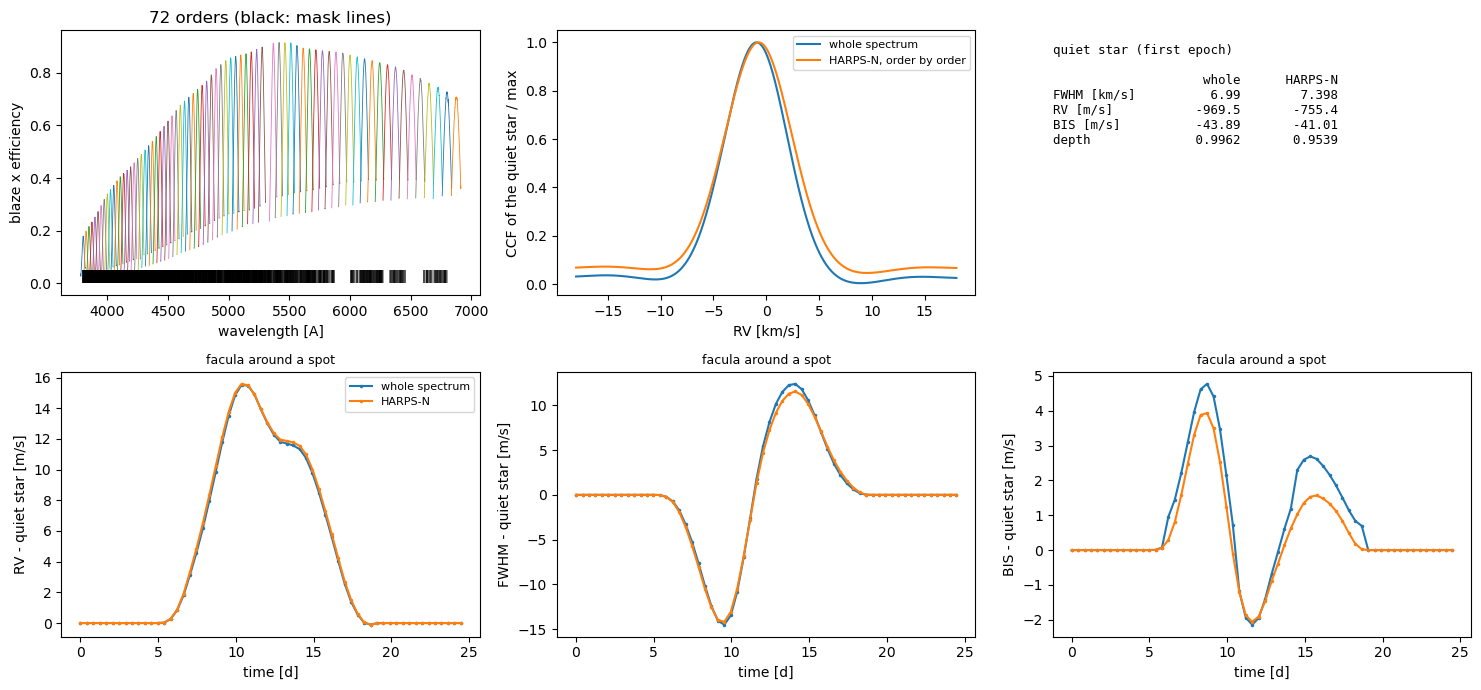

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
# blaze x efficiency of every order, and the mask lines
ax = axes[0, 0]
eff_orders = np.interp(wave_orders, *(np.asarray(x)[np.argsort(efficiency[0])] for x in efficiency))
for w, b, e in zip(wave_orders, blaze_orders, eff_orders):
    ax.plot(w, b * e, lw=0.6)
ax.vlines(wvm, 0, 0.05, color='k', lw=0.3)
ax.set_xlabel('wavelength [A]')
ax.set_ylabel('blaze x efficiency')
ax.set_title('72 orders (black: mask lines)')
# CCF of the quiet star (first epoch), normalised to its continuum
ax = axes[0, 1]
for ss, label in ((no_instrument, 'whole spectrum'), (harpsn_run, 'HARPS-N, order by order')):
    c = ss.ccf_var[0]
    ax.plot(ss.ccf_rv / 1000, c / np.max(c), label=label)
ax.set_xlabel('RV [km/s]')
ax.set_ylabel('CCF of the quiet star / max')
ax.legend(fontsize=8)
ax = axes[0, 2]
ax.axis('off')
rows = [('FWHM [km/s]', 'fwhm_var', 1e-3), ('RV [m/s]', 'rv_var', 1), ('BIS [m/s]', 'bis_var', 1)]
text = 'quiet star (first epoch)\n\n%-12s %12s %12s\n' % ('', 'whole', 'HARPS-N')
for label, attr, scale in rows:
    text += '%-12s %12.4g %12.4g\n' % (label, scale * getattr(no_instrument, attr)[0], scale * getattr(harpsn_run, attr)[0])
depth = lambda ss: 1 - np.min(ss.ccf_var[0]) / np.max(ss.ccf_var[0])     # the contrast of a sum of orders is not comparable
text += '%-12s %12.4g %12.4g\n' % ('depth', depth(no_instrument), depth(harpsn_run))
ax.text(0, 0.95, text, family='monospace', va='top', fontsize=9)
# time series of the 'facula around a spot' case, relative to the quiet star
for ax, (attr, label) in zip(axes[1], (('rv_var', 'RV'), ('fwhm_var', 'FWHM'), ('bis_var', 'BIS'))):
    for ss, lab in ((no_instrument, 'whole spectrum'), (harpsn_run, 'HARPS-N')):
        v = getattr(ss, attr)
        ax.plot(ss.obs_times, v - v[0], '.-', ms=3, label=lab)
    ax.set_xlabel('time [d]')
    ax.set_ylabel('%s - quiet star [m/s]' % label)
    ax.set_title(name, fontsize=9)
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

The instrument broadens the CCF of the quiet star (FWHM 6.99 → 7.40 km/s: the instrumental profile, c/R ≈ 2.5 km/s, added in quadrature would give 7.44 km/s) and makes it shallower. The lines are weighted differently, so the RV of the quiet star moves by ~200 m/s (the convective blueshift differs from line to line): the CCF of every order is normalised before the orders are added, so **every order counts the same** whatever its flux, the lines in the gaps between the orders are left out and those in the overlaps of two orders count twice. The blaze only changes the weights of the lines **inside** an order, and the efficiency (and a flattening of the spectra) has **no effect**: a factor common to a whole order disappears in the normalisation of its CCF (tested: ≤ 0.002 m/s on the RV, FWHM and BIS). The activity signals of the regions keep their shape: here the RV is almost the same, the FWHM amplitude is ~7 % smaller and the BIS amplitude 20-40 % smaller (the instrumental profile smooths the asymmetries of the CCF).

With an instrument, the bisector added in `rv_treatment` (here the Dumusque bisector of the spot) is evaluated on the mean of the CCFs of the orders, whose heights are those of one CCF, as the polynomial expects (the sum of the 72 orders reaches ~33). The same order-by-order computation is tested against the old StarSim in `tests/old_version` (cases `hr_harpsn` and `sdo_real_harpsn`).

## 8. Active regions from 2D maps of the disc (e.g. SDO)

Instead of circular regions, the spots and faculae can be given as **images of the disc**, one spot map and one facula map per epoch. `active_region_mask(folder)` finds them in a folder, and `StarSim(..., active_regions_mask=maps)` then uses them instead of `active_regions_map` (the two cannot be combined; planets can be added on top).

**Files.** For every epoch t [days]:

| file | content |
|---|---|
| `spot_map_{t}.npy` or `spot_map_{t}.txt` | fraction of every pixel covered by spots: 0 = quiet, 1 = spot (binary masks work) |
| `faculae_map_{t}.npy` or `faculae_map_{t}.txt` | the same for the faculae |

* `{t}` is any number (`12`, `12.5`, `2459000.25`); `maps.times` gives the epochs found, sorted. Use them as the times of `StarSim`: every epoch of `StarSim` must have its maps. If one of the two maps is missing for an epoch, it is taken as 0 everywhere.
* Every map is a square image of the visible disc, the **disc filling the image** (its diameter is the size of the image). Pixels outside the disc are ignored (they can be NaN). Any size works (up to 4096 x 4096 or more).
* Text files have the values separated by spaces, tabs or commas, one image row per line. Other names: `active_region_mask(folder, spot_pattern='mask_spot_{time}', faculae_pattern='mask_fac_{time}')`.
* **Speed.** Save the maps as `.npy`, ideally as `uint8` or `bool` masks: a 4096 x 4096 map then takes ~0.01 s per epoch (read and projected), against ~2 s to read a text map. With `active_region_mask(folder, cache_npy=True)` every text map is converted to `.npy` (in the same folder) the first time it is read. The epochs are processed in `n_threads` parallel threads (default 4). With `cache_filling_factors=True` the filling factors of every epoch are saved in the folder (one hidden file per number of rings), and a new run with the same maps and the same number of rings does not read the maps again (useful when only the spectra, the grids or the mode change).

**Orientation.** The horizontal axis of the image is the projected equator of the star, with the rotation moving the regions from **left to right** (east → west on the Sun, with north up). The vertical axis is the projected rotation axis, with **north up**. `origin='upper'` (default) means that row 0 of the array is the top of the image, as `np.loadtxt` reads a text image and as `plt.imshow` shows it; use `origin='lower'` if row 0 is the bottom, and `flip_horizontal=True` if the regions move from right to left in your images. The inclination of the star given to `StarSim` should be that of the images (for the Doppler shifts in ccf mode).

**How it works.** For a grid of `N_rings` rings, every pixel is assigned once to a cell of the grid (the cell that contains it on the disc; computed once per image size, ~0.1 s for 4096 x 4096). At every epoch the spot and facula filling factors of a cell are the means of the two maps over its pixels; in every cell the spots are on top of the faculae, and the planets on top of both. Then the light curve, spectra or CCFs are computed exactly as with circular regions. With many rings and small maps, the narrowest rings at the limb can have cells without any pixel: they are taken as quiet (a warning is given if they cover more than 0.1% of the disc).

**Example.** Set `maps_folder` to your folder. If it is `None`, demo maps are drawn from the `facula around a spot` case of section 3 (1024 x 1024 pixels, in a temporary folder), so that the light curve from the maps can be compared with the one from the circular regions.

In [28]:
# maps_folder = None          # put here the folder with spot_map_{t}.npy/.txt and faculae_map_{t}.npy/.txt
maps_folder = '/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/My Drive/storage/maps_active_2015_09_12_ccf_notnorm/'          # put here the folder with spot_map_{t}.npy/.txt and faculae_map_{t}.npy/.txt


def draw_maps(ss, folder, n_pix=1024):
    """Spot and facula maps (origin='upper') of the circular regions of a StarSim run, one pair per epoch."""
    os.makedirs(folder, exist_ok=True)
    c = (2 * np.arange(n_pix) + 1) / n_pix - 1
    y, z = c[None, :], -c[:, None]                       # columns: left to right; rows: top (north) to bottom
    r2 = y**2 + z**2
    x = np.sqrt(np.clip(1 - r2, 0, None))                # towards the observer
    for k, t in enumerate(ss.obs_times):
        spot = np.zeros((n_pix, n_pix), dtype=np.uint8)
        facula = np.zeros_like(spot)
        for i, region in enumerate(ss.active_regions_map):
            vx, vy, vz = ss.regions_vec[k, i]                # centre of the region (x towards the observer)
            covered = (r2 <= 1) & (x * vx + y * vy + z * vz >= np.cos(ss.regions_pos[k, i, 2]))
            (spot if region.type == 'sp' else facula)[covered] = 1
        facula[spot > 0] = 0                             # the spots are on top of the faculae
        np.save(os.path.join(folder, 'spot_map_%.6f.npy' % t), spot)
        np.save(os.path.join(folder, 'faculae_map_%.6f.npy' % t), facula)

if maps_folder is None:
    import tempfile
    maps_folder = os.path.join(tempfile.gettempdir(), 'sunsim_demo_maps')
    draw_maps(photometry['facula around a spot'], maps_folder)

maps = active_region_mask(maps_folder, origin='upper')
print('%d epochs, from t = %.2f to %.2f d' % (len(maps.times), maps.times[0], maps.times[-1]))

89 epochs, from t = 0.00 to 88.00 d


**How many rings for the resolution of the maps?** The rings have the same angular width on the sphere, so in projection they get narrower towards the limb: the outermost ring is only ~(π/(2N))²/2 of the radius wide. With too many rings for the size of the maps, the cells of the outer rings contain no pixel at all, and their filling factors are 0 whatever the maps (the regions at the limb are lost). The limit grows as √(resolution): about 10 rings for 64 × 64 maps, 40 for 1024 × 1024 and 80 for 4096 × 4096.

`max_rings(resolution)` gives the largest `N_rings` for which every cell has at least one pixel (`resolution` = n for n × n maps, or `(n_rows, n_cols)`); `max_rings(resolution, min_pixels=k)` asks for k pixels in every cell, so that the filling factors at the limb are not only 0 or 1 with binary masks. `pixels_per_cell(resolution, N_rings)` gives the number of pixels of every cell. They use the exact projection of the simulation and are not needed to run it: they are a tool to choose `N_rings` (~0.1 s for 1024 × 1024, ~2 s for 4096 × 4096).

maps of 944 x 944 pixels:


  at most  38 rings with >=   1 pixel(s) in every cell
  at most  33 rings with >=  10 pixel(s) in every cell
  at most  16 rings with >= 100 pixel(s) in every cell
  N_rings_phot = 15: 535 cells, 139 to 2712 pixels per cell
  N_rings_ccf = 30: 2218 cells, 13 to 662 pixels per cell


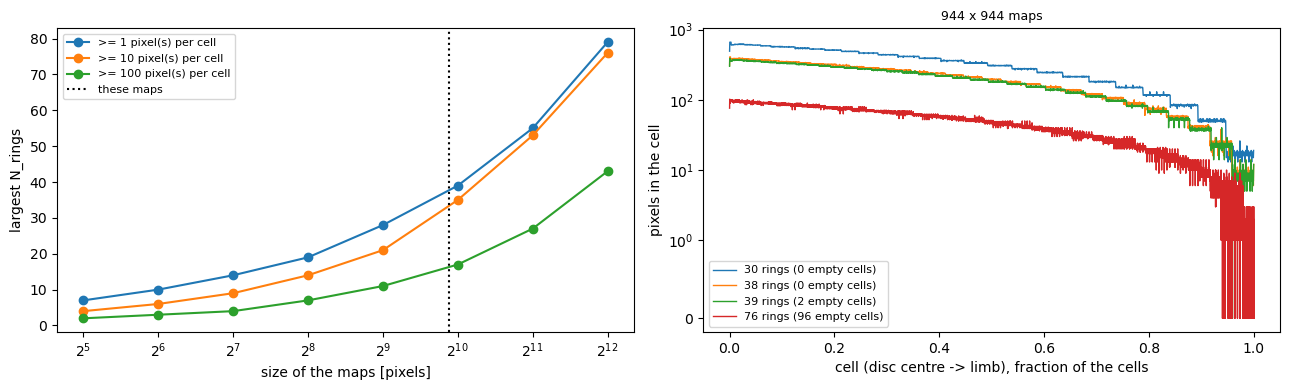

In [29]:
map_shape = maps.load(maps.times[0])[0].shape
print('maps of %d x %d pixels:' % map_shape)
for k in (1, 10, 100):
    print('  at most %3d rings with >= %3d pixel(s) in every cell' % (max_rings(map_shape, min_pixels=k), k))
for name, n in (('N_rings_phot', N_rings_phot), ('N_rings_ccf', N_rings_ccf)):
    npix = pixels_per_cell(map_shape, n)
    print('  %s = %d: %d cells, %d to %d pixels per cell%s' % (name, n, len(npix), npix.min(), npix.max(),
          '' if npix.min() > 0 else '  -> %d EMPTY cells' % np.sum(npix == 0)))

resolutions = np.array([32, 64, 128, 256, 512, 1024, 2048, 4096])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in (1, 10, 100):
    axes[0].plot(resolutions, [max_rings(n, min_pixels=k) for n in resolutions], 'o-', label='>= %d pixel(s) per cell' % k)
axes[0].axvline(map_shape[0], color='k', ls=':', label='these maps')
axes[0].set_xscale('log', base=2)
axes[0].set_xlabel('size of the maps [pixels]')
axes[0].set_ylabel('largest N_rings')
axes[0].legend(fontsize=8)
n_max = max_rings(map_shape)
for n in (N_rings_ccf, n_max, n_max + 1, 2 * n_max):
    npix = pixels_per_cell(map_shape, n)
    axes[1].plot(np.arange(len(npix)) / len(npix), npix, lw=1, label='%d rings (%d empty cells)' % (n, np.sum(npix == 0)))
axes[1].set_yscale('symlog', linthresh=1)
axes[1].set_xlabel('cell (disc centre -> limb), fraction of the cells')
axes[1].set_ylabel('pixels in the cell')
axes[1].set_title('%d x %d maps' % map_shape, fontsize=9)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

2D maps: 89 epochs, 15 rings (535 cells)


Date 0.0000. ff_ph=94.512%. ff_sp=0.011%. ff_fc=5.476%. [1/89] 0.4 s, ~36.0 s left   

Date 1.0000. ff_ph=94.899%. ff_sp=0.011%. ff_fc=5.091%. [2/89] 0.4 s, ~17.8 s left   

Date 2.0000. ff_ph=95.136%. ff_sp=0.006%. ff_fc=4.858%. [3/89] 0.4 s, ~11.8 s left   

Date 3.0000. ff_ph=95.124%. ff_sp=0.006%. ff_fc=4.870%. [4/89] 0.4 s, ~8.7 s left   

...

Date 84.0000. ff_ph=94.935%. ff_sp=0.044%. ff_fc=5.021%. [85/89] 4.6 s, ~0.2 s left   

Date 85.0000. ff_ph=94.895%. ff_sp=0.035%. ff_fc=5.070%. [86/89] 4.6 s, ~0.2 s left   

Date 86.0000. ff_ph=94.841%. ff_sp=0.026%. ff_fc=5.134%. [87/89] 4.7 s, ~0.1 s left   

Date 87.0000. ff_ph=94.783%. ff_sp=0.026%. ff_fc=5.191%. [88/89] 4.7 s, ~0.1 s left   

Date 88.0000. ff_ph=95.137%. ff_sp=0.025%. ff_fc=4.838%. [89/89] 4.8 s, ~0.0 s left   

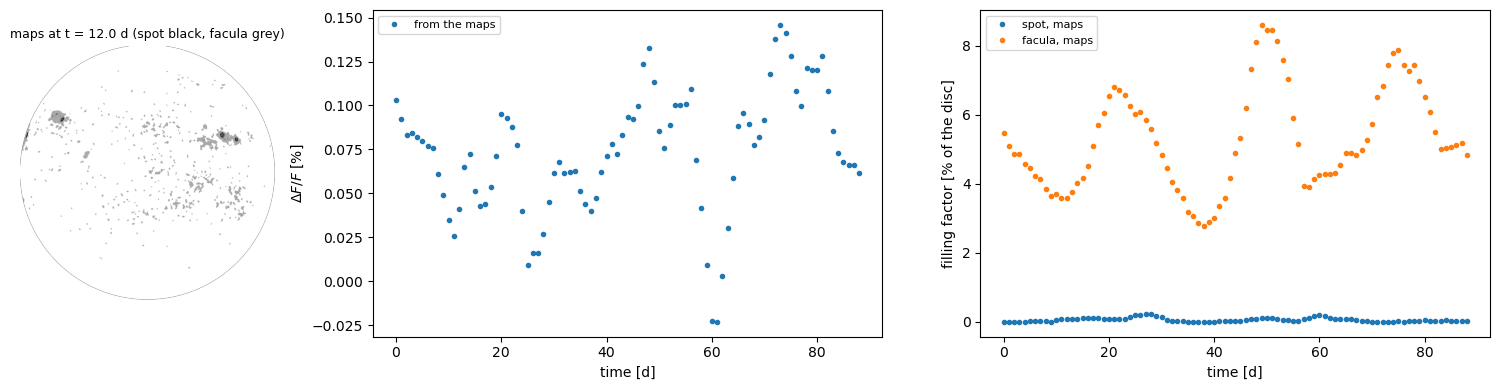

In [30]:
from_maps = StarSim(maps.times, N_rings_phot, inclination=inclination, rotation_period=rotation_period,
                    differential_rotation=differential_rotation, active_regions_mask=maps, mode=['photometry'],
                    stellar_radius=stellar_radius,
                    flux_grid_qp=flux_grid_quiet.grid, flux_grid_sp=flux_grid_sp.grid, flux_grid_fc=flux_grid_fc.grid)
from_maps.generate_timeseries()

k_mid = int(np.argmin(np.abs(maps.times - rotation_period / 2)))
spot_map, facula_map = maps.load(maps.times[k_mid])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2, 2]})
axes[0].imshow(spot_map + 0.5 * facula_map, cmap='gray_r', origin='upper')
axes[0].set_title('maps at t = %.1f d (spot black, facula grey)' % maps.times[k_mid], fontsize=9)
axes[0].set_axis_off()
axes[1].plot(from_maps.obs_times, relative_flux(from_maps), '.', label='from the maps')
axes[2].plot(from_maps.obs_times, from_maps.ff_sp, '.', label='spot, maps')
axes[2].plot(from_maps.obs_times, from_maps.ff_fc, '.', label='facula, maps')
if 'sunsim_demo_maps' in maps_folder:                    # demo: compare with the circular regions
    regions = photometry['facula around a spot']
    axes[1].plot(regions.obs_times, relative_flux(regions), '-', label='circular regions')
    axes[2].plot(regions.obs_times, regions.ff_sp, '-', color='C0', alpha=0.5, label='spot, regions')
    axes[2].plot(regions.obs_times, regions.ff_fc, '-', color='C1', alpha=0.5, label='facula, regions')
axes[1].set_ylabel('$\\Delta F / F$ [%]')
axes[2].set_ylabel('filling factor [% of the disc]')
for ax in axes[1:]:
    ax.set_xlabel('time [d]')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The same maps work in the other modes: `mode=['spectroscopy']` with the spectroscopy grids, or `mode=['ccf']` with the CCF grids of section 7. A planet can be added with `planet=...`. The projection of the pixels is computed again for another number of rings.

2D maps: 89 epochs, 30 rings (2218 cells)


Date 0.0000. ff_ph=94.512%. ff_sp=0.011%. ff_fc=5.477%. [1/89] 0.2 s, ~19.9 s left   

Date 1.0000. ff_ph=94.899%. ff_sp=0.011%. ff_fc=5.090%. [2/89] 0.2 s, ~9.9 s left   

Date 2.0000. ff_ph=95.137%. ff_sp=0.006%. ff_fc=4.857%. [3/89] 0.2 s, ~6.5 s left   

Date 3.0000. ff_ph=95.123%. ff_sp=0.006%. ff_fc=4.871%. [4/89] 0.2 s, ~4.9 s left   

...

Date 84.0000. ff_ph=94.936%. ff_sp=0.044%. ff_fc=5.020%. [85/89] 4.8 s, ~0.2 s left   

Date 85.0000. ff_ph=94.897%. ff_sp=0.035%. ff_fc=5.068%. [86/89] 4.8 s, ~0.2 s left   

Date 86.0000. ff_ph=94.841%. ff_sp=0.026%. ff_fc=5.134%. [87/89] 4.9 s, ~0.1 s left   

Date 87.0000. ff_ph=94.781%. ff_sp=0.026%. ff_fc=5.193%. [88/89] 4.9 s, ~0.1 s left   

Date 88.0000. ff_ph=95.138%. ff_sp=0.025%. ff_fc=4.837%. [89/89] 5.0 s, ~0.0 s left   

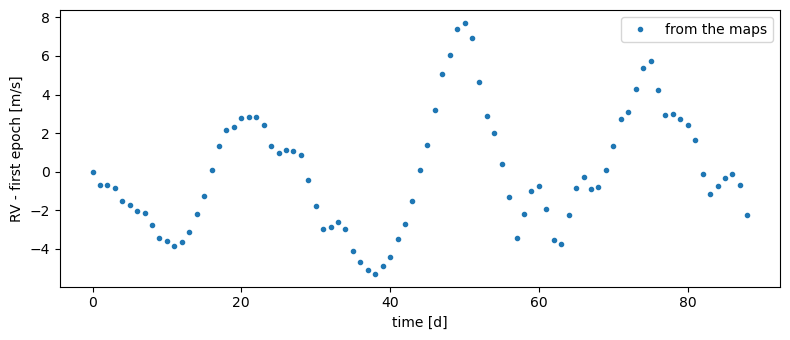

In [31]:
maps_ccf = StarSim(maps.times, N_rings_ccf, inclination=inclination, rotation_period=rotation_period,
                   differential_rotation=differential_rotation, active_regions_mask=maps, mode=['ccf'],
                   stellar_radius=stellar_radius, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
maps_ccf.generate_timeseries()

plt.figure(figsize=(8, 3.5))
plt.plot(maps_ccf.obs_times, maps_ccf.rv_var - maps_ccf.rv_var[0], '.', label='from the maps')
if 'sunsim_demo_maps' in maps_folder:
    regions_ccf = ccf_runs['facula around a spot']
    plt.plot(regions_ccf.obs_times, regions_ccf.rv_var - regions_ccf.rv_var[0], '-', label='circular regions')
plt.xlabel('time [d]')
plt.ylabel('RV - first epoch [m/s]')
plt.legend()
plt.tight_layout()
plt.show()